<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/HybridQNN_PreprocessingDAE_AdversarialRobustness_Yang2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid classical-quantum network with a denoising pre-encoding layer: Yang et al. (2024) step by step

This notebook re-implements, runs and checks the whole experimental part of

> Yongxi Yang, Shibin Zhang, Lili Yan and Yan Chang,
> "Hybrid Classical Quantum Neural Network with High Adversarial Robustness",
> *Proceedings of Machine Learning Research* vol. 245, pp. 1-9, 2024 (2024 International Conference on Machine Learning and Intelligent Computing, editors N. Zeng and R. B. Pachori).
> https://proceedings.mlr.press/v245/yongxi24a.html

**What the paper does.** A quantum neural network (QNN) is fragile: a tiny FGSM perturbation of the input flips its prediction. The authors put a **denoising autoencoder (DAE)** in front of the
quantum circuit as a "pre-encoding layer": the input is first reconstructed by the DAE (which removes noise and adversarial perturbation) and only then encoded into the circuit.
They test it on **Iris** (Table 1: MSE and cosine similarity of noisy / FGSM data before and after the DAE; Fig. 4: accuracy under FGSM with epsilon 0.15 / 0.30 / 0.45 / 0.60) and on
**4-class MNIST** (Fig. 5: clean training accuracy with and without the layer; Fig. 6: example images; Table 2: accuracy of the plain QNN, the QNN with the DAE and an adversarially trained QNN at epsilon 0.15 / 0.30 / 0.45).

**What this notebook does.** It builds exactly these two experiments with a **PennyLane-style `StronglyEntanglingLayers` circuit** (simulated exactly in PyTorch so that the FGSM gradient flows through the circuit,
and **asserted equal to the real PennyLane QNode**), trains the plain QNN, the QNN with the DAE, the adversarially trained QNN, and a **classical counterpart** (a small MLP, with and without the same DAE, and adversarially trained) on identical inputs,
attacks all of them with FGSM at the paper's epsilons, and prints the paper's numbers next to ours with a verdict per claim. The attack is evaluated in two ways: **static** (the paper's pipeline: adversarial images are crafted against the plain QNN and then fed through the DAE) and
**adaptive** (an attacker who differentiates through the DAE as well, which the paper never tests).

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime and use *Runtime -> Run all*. The first cell installs PennyLane (pinned); if Colab asks to restart the session, restart and run all again.
No GPU, no IBM Quantum account and no Hugging Face token are needed (MNIST and Iris are public; if you ever point the code at a gated dataset, put your own token under Colab *Secrets* as `HF_TOKEN`).
`FAST_MODE = True` is a class demo (3,000 training images, 600 test images, 1 seed for MNIST, 5 seeds for Iris; a few minutes); `FAST_MODE = False` uses all digits 0-3 of MNIST (24,754 training / 4,157 test images), 3 MNIST seeds and 20 Iris seeds.
The recorded run in this notebook is the full one (`FAST_MODE = False`); it took 66.8 minutes on a CPU shared with about ten other jobs (the FAST version needs about 5 minutes). The wall-clock time is printed in the last code cell.

**What you get at the end.** Table 1 and Fig. 4 for Iris, Fig. 5, Fig. 6 and Table 2 for MNIST re-drawn with error bars over seeds, a classical-counterpart comparison, the static-versus-adaptive study, the circuit that was executed (drawn and asserted), and a verdict per claim.

## The paper in one page

**Problem.** Quantum classifiers, like classical ones, are fooled by small input perturbations. The more complex the classifier, the more vulnerable it is.

**Idea.** Replace the classical layer in front of the quantum layer by a **preprocessing (pre-encoding) layer** that denoises and reconstructs the input: a denoising autoencoder (Vincent et al. 2010), trained **separately** on noisy -> clean data, then frozen and placed in front of the data-encoding stage of the QNN
(structure of Fig. 3: preprocessing layer -> encoding -> parameterised quantum circuit -> measurement). The paper argues that this is much cheaper than adversarial training because the layer is trained independently of the QNN.

**Noise models.** (i) Gaussian noise added to the data; (ii) FGSM adversarial examples, $x_{adv} = x + \epsilon\,\mathrm{sign}(\nabla_x J(\theta, x, y))$ (Eq. 4).
**Similarity metrics (Eqs. 2, 3).** Mean squared error and cosine similarity between the (noisy / FGSM / reconstructed) data and the original data.

**Experiments and claims.**

| Experiment | Claim (paper values) |
|---|---|
| Iris, Table 1 | Noisy data: MSE 0.263 -> 0.173 and cosine 0.832 -> 0.895 after the DAE. FGSM data: MSE 0.211 -> 0.176 and cosine 0.873 -> 0.910 |
| Iris, Fig. 4 (text) | Accuracy of the model with the layer under FGSM: 93.3 % (eps 0.15), 90 % (0.30), 86.67 % (0.45), 73.33 % (0.60); the curve without the layer is lower (shown in the figure only, no numbers) |
| 4-class MNIST, Fig. 5 | The layer "basically does not affect" the accuracy on clean data (training accuracy curves with and without it) |
| 4-class MNIST, Table 2 | Accuracy at eps 0.15 / 0.30 / 0.45: plain QNN 42.2 / 24.6 / 13.7 %, QNN with the layer 89.9 / 61.6 / 34.9 %, adversarially trained QNN 67.4 / 27.5 / 16.4 % |
| Conclusion | The layer beats adversarial training and is cheaper because it is trained separately |

## What follows the paper and what had to be chosen

The paper gives no code and omits almost every hyper-parameter. Every item below that is not in the paper is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Quantum circuit | "parameterised quantum circuit", Z-basis measurement; gates, depth, qubits not given | `StronglyEntanglingLayers` (Rot gates + ring of CNOTs, the PennyLane template), measurement of $\langle Z\rangle$ on one qubit per class. Iris: 4 qubits, 3 layers; MNIST: 10 qubits, 4 layers. CHOICE |
| Encoding | angle or amplitude encoding mentioned in Sec. 2.2.1 | Iris: angle encoding (`RX(pi * x)`, features scaled to [0, 1]); MNIST: amplitude encoding of the 784 pixels (zero-padded to 1,024 amplitudes = 10 qubits). CHOICE; this also means there is **no trainable classical layer before the circuit**, in line with "replacing the classical network layer preceding the quantum layer with a preprocessing layer" |
| Output | prediction from expectation values | logits = 5 x $\langle Z_q\rangle$ for the first 3 (Iris) or 4 (MNIST) qubits, cross-entropy loss. CHOICE |
| Preprocessing layer | denoising autoencoder, trained first, then frozen and combined with the QNN | Iris DAE 4-16-2-16-4 (linear output); MNIST DAE 784-256-64-256-784 (sigmoid output); MSE loss; trained on Gaussian-noisy -> clean data of the training split only. CHOICE of sizes |
| Gaussian noise | not stated | Iris sigma = 0.5 (the paper's MSE of 0.263 equals sigma squared for sigma = 0.51 when nothing is clipped); MNIST sigma = 0.3 for training and testing, images clipped to [0, 1]. CHOICE |
| FGSM | Eq. 4, epsilons 0.15 / 0.30 / 0.45 (/ 0.60 for Iris) | the same formula; Iris features in [0, 1] without clipping (Eq. 4 has no clip; the paper's FGSM MSE of 0.211 is about 0.46 squared, i.e. epsilon 0.45 unclipped, which is used for Table 1); MNIST pixels clipped to [0, 1] |
| Who is attacked | Fig. 6: adversarial samples are generated and then passed through the pre-encoding layer | **static** attack = FGSM against the plain QNN, then fed to every model (main number, the paper's pipeline). **adaptive** attack = FGSM against each model end to end (extra, not in the paper) |
| Iris split | accuracies 93.3 / 90 / 86.67 / 73.33 % are multiples of 1/30 | stratified 80/20 split (30 test flowers), several seeds, scaler fitted on the training split. CHOICE |
| MNIST classes | "4-class classification" | digits 0, 1, 2, 3. CHOICE |
| MNIST sizes | not stated | FAST: 3,000 training / 600 test images; full: all 24,754 / 4,157 images of digits 0-3 |
| Adversarial training baseline | "selected generated adversarial examples are incorporated into the training set" | FGSM images of the plain QNN at eps 0.15, 0.30, 0.45 (one third each), as many as 50 percent of the training set, merged with the clean training images; a fresh QNN is trained on the union. CHOICE |
| Optimiser, epochs | not stated | Adam, learning rate 0.05, batch 64, 12 (FAST) / 10 epochs for MNIST, the epoch with the lowest validation loss is kept (10 % of the training images, never the test images); Iris: full batch, fixed number of epochs |
| Classical counterpart | none in the paper | MLP 784-64-4 (MNIST) / 4-8-3 (Iris) with ReLU, trained, attacked and defended on identical inputs; also with the same DAE and adversarially trained |
| Simulator | not stated | exact state-vector simulation, no shots. The PyTorch simulator is asserted equal to the PennyLane QNode (maximum difference < 1e-9). No hardware |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch, Pillow and huggingface_hub.
# Only PennyLane has to be added; it is used to assert the simulator and to draw the circuit.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")

PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE   = False           # True: class demo (a few minutes). False: all digits 0-3 of MNIST, 3 seeds, 20 Iris seeds (see the budgets below)
SEED        = 42              # CHOICE: the paper gives no seed
DATA_DIR    = "data"          # cache for the downloaded MNIST files (relative to the working directory)
IBM_TOKEN   = ""              # not used: the paper simulates everything, there is no hardware cell in this notebook
TORCH_THREADS = 1             # CPU threads for PyTorch (1 is fastest for these small tensors, also on a loaded machine)

# ---- Iris experiment (Table 1 and Fig. 4) ----
IRIS_TEST_SIZE = 0.2          # 30 test flowers: the paper's accuracies are multiples of 1/30
IRIS_SIGMA     = 0.5          # CHOICE: Gaussian noise std (features in [0, 1])
IRIS_EPS       = (0.15, 0.30, 0.45, 0.60)   # Fig. 4
IRIS_T1_EPS    = 0.45         # CHOICE: epsilon of the FGSM data in Table 1 (MSE 0.211 ~ 0.46 squared)
IRIS_LAYERS    = 3            # CHOICE: StronglyEntanglingLayers depth (4 qubits, 36 trainable parameters)
IRIS_EPOCHS, IRIS_LR = 150, 0.1      # full-batch Adam
IRIS_DAE_EPOCHS, IRIS_DAE_LR = 800, 0.01
# ---- MNIST experiment (Fig. 5, Fig. 6, Table 2) ----
CLASSES    = (0, 1, 2, 3)     # CHOICE: the paper says "4-class classification"
MNIST_EPS  = (0.15, 0.30, 0.45)      # Table 2
N_QUBITS_M = 10               # amplitude encoding of 784 pixels padded to 1,024 amplitudes
M_LAYERS   = 4                # CHOICE: StronglyEntanglingLayers depth (120 trainable parameters)
BATCH, QNN_LR = 64, 0.05
DAE_SIGMA, DAE_EPOCHS, DAE_LR = 0.3, 10, 1e-3
ADV_FRACTION = 0.5            # CHOICE: adversarial images added for adversarial training = this share of the training set
VAL_FRACTION = 0.1            # CHOICE: share of the training images used to pick the best epoch
LOGIT_SCALE  = 5.0            # CHOICE: logits = LOGIT_SCALE * <Z>

if FAST_MODE:
    IRIS_SEEDS = 5            # independent splits / initialisations
    N_TRAIN, N_TEST = 3000, 600     # MNIST images of digits 0-3 (full: 24,754 / 4,157)
    EPOCHS = 12
    MNIST_SEEDS = 1
else:
    IRIS_SEEDS = 20
    N_TRAIN, N_TEST = None, None    # None = all images of digits 0-3
    EPOCHS = 10
    MNIST_SEEDS = 3

In [3]:
import os, io, math, time, copy, warnings, importlib.metadata as md
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
from PIL import Image
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Hugging Face token: only needed for gated datasets. MNIST is public, so an empty token is fine.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

matplotlib.rcParams["figure.dpi"] = 80                     # keeps the saved figures small
torch.set_num_threads(TORCH_THREADS)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T_START = time.time()
print("torch", torch.__version__, "| pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
print("FAST_MODE =", FAST_MODE, "| Iris seeds", IRIS_SEEDS, "| MNIST seeds", MNIST_SEEDS, "| N_TRAIN", N_TRAIN, "| N_TEST", N_TEST, "| epochs", EPOCHS)

torch 2.14.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6
FAST_MODE = False | Iris seeds 20 | MNIST seeds 3 | N_TRAIN None | N_TEST None | epochs 10


## 1. Iris and 4-class MNIST, downloaded

* **Iris** (Fisher 1936): 150 flowers, 4 measurements, 3 species. It ships inside scikit-learn (the UCI file), so no download is needed.
* **MNIST**: the official parquet files of the Hugging Face repository `ylecun/mnist` (fallback: `keras.datasets.mnist`, available in Colab). Only digits 0, 1, 2, 3 are used by the experiments; all ten digits are kept for the exploration section.

In [4]:
# ---- Iris ----
_iris = load_iris()
IRIS_X, IRIS_y = _iris.data.astype(np.float64), _iris.target
IRIS_FEATS, IRIS_NAMES = list(_iris.feature_names), list(_iris.target_names)

# ---- MNIST ----
def load_mnist():
    cache = os.path.join(DATA_DIR, "mnist_cache.npz")
    if os.path.exists(cache):
        z = np.load(cache); return {k: z[k] for k in z.files if k != "origin"}, str(z["origin"]) + " (cached)"
    try:
        from huggingface_hub import hf_hub_download
        out = {}
        for sp in ("train", "test"):
            p = hf_hub_download("ylecun/mnist", f"mnist/{sp}-00000-of-00001.parquet", repo_type="dataset",
                                local_dir=os.path.join(DATA_DIR, "hf"), token=HF_TOKEN or None)
            df = pd.read_parquet(p)
            out["X" + sp] = np.stack([np.asarray(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]).astype(np.uint8)
            out["y" + sp] = df["label"].to_numpy().astype(np.int64)
        origin = "huggingface:ylecun/mnist"
    except Exception as e:
        print("Hugging Face download failed (%s: %s); falling back to keras.datasets" % (type(e).__name__, str(e)[:80]))
        from tensorflow.keras import datasets as kd
        (xtr, ytr), (xte, yte) = kd.mnist.load_data()
        out = dict(Xtrain=xtr, ytrain=ytr.astype(np.int64), Xtest=xte, ytest=yte.astype(np.int64)); origin = "keras.datasets"
    np.savez_compressed(cache, origin=np.array(origin), **out)
    return out, origin

MN, MN_ORIGIN = load_mnist()
print("Iris :", IRIS_X.shape, "| MNIST:", MN["Xtrain"].shape, MN["Xtest"].shape, "| origin:", MN_ORIGIN)

def mnist_split(seed):
    # MNIST digits CLASSES: random subsets (seeded), pixels in [0, 1] as flat float32 vectors, labels 0..3, 10 % validation part
    r = np.random.default_rng(seed)
    def pick(X, y, n):
        idx = np.where(np.isin(y, CLASSES))[0]; idx = r.permutation(idx)[:n]
        return torch.tensor(X[idx].reshape(len(idx), -1), dtype=torch.float32).div_(255.0), torch.tensor(np.searchsorted(CLASSES, y[idx]))
    Xa, ya = pick(MN["Xtrain"], MN["ytrain"], N_TRAIN); Xte, yte = pick(MN["Xtest"], MN["ytest"], N_TEST)
    nva = int(round(VAL_FRACTION * len(Xa)))                      # CHOICE: the first 10 % of the shuffled images validate
    return dict(Xtr=Xa[nva:], ytr=ya[nva:], Xva=Xa[:nva], yva=ya[:nva], Xte=Xte, yte=yte)

MS0 = mnist_split(SEED)
print({k: tuple(v.shape) for k, v in MS0.items()}, "| train class counts", np.bincount(MS0["ytr"].numpy()).tolist(),
      "| test class counts", np.bincount(MS0["yte"].numpy()).tolist())

Iris : (150, 4) | MNIST: (60000, 28, 28) (10000, 28, 28) | origin: huggingface:ylecun/mnist (cached)
{'Xtr': (22279, 784), 'ytr': (22279,), 'Xva': (2475, 784), 'yva': (2475,), 'Xte': (4157, 784), 'yte': (4157,)} | train class counts [5345, 6031, 5358, 5545] | test class counts [980, 1135, 1032, 1010]


## Dataset Exploration and Visualisation

Everything below is computed from the real data: shapes, feature names, original labels and class counts, the class distribution (bar charts), real example images, and two-dimensional projections in which
**every point is one real observation coloured by its ground-truth label**. For Iris the projection is the PCA of the four measurements; for MNIST it is the PCA of the pixels
(MNIST has no attack-family labels: the classes are the digits). Each projection is shown first as raw PCA coordinates (fitted on the training split only) and then scaled to $[0, \pi]$ (the range of a rotation angle; the scaler is fitted on the training split only).
The paper's circuits do not encode these two coordinates: Iris is encoded with four angles, MNIST with 1,024 amplitudes; the projections show how separable the real classes are.

### Shapes, feature names, original labels and class counts

In [5]:
# ---- real-dataset facts ----
print("=== Iris (UCI / scikit-learn) ===")
print("shape        :", IRIS_X.shape, "(150 flowers x 4 features)")
print("feature names:", IRIS_FEATS)
print("original labels:", dict(zip(range(3), IRIS_NAMES)), "| counts", np.bincount(IRIS_y).tolist())
print("feature ranges :", {f: (round(float(IRIS_X[:, i].min()), 1), round(float(IRIS_X[:, i].max()), 1)) for i, f in enumerate(IRIS_FEATS)})

print("\n=== MNIST (%s) ===" % MN_ORIGIN)
feat = [f"pixel_{r}_{c}" for r in range(28) for c in range(28)]
print("full shape   : %d training + %d test images, each 28 x 28 grey-scale = %d features" % (len(MN["ytrain"]), len(MN["ytest"]), len(feat)))
print("feature names:", feat[:3], "...", feat[-1], "(intensities 0..255, scaled to [0, 1] here)")
print("original labels: digits 0..9")
display(pd.DataFrame({"digit": range(10), "train (full)": np.bincount(MN["ytrain"], minlength=10), "test (full)": np.bincount(MN["ytest"], minlength=10)}).set_index("digit").T)
print("classes used by the experiment:", list(CLASSES), "(relabelled 0..3)")
print("subsets this run: train", np.bincount(MS0["ytr"].numpy()).tolist(), "| validation", np.bincount(MS0["yva"].numpy()).tolist(), "| test", np.bincount(MS0["yte"].numpy()).tolist())

=== Iris (UCI / scikit-learn) ===


shape        : (150, 4) (150 flowers x 4 features)
feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
original labels: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')} | counts [50, 50, 50]
feature ranges : {'sepal length (cm)': (4.3, 7.9), 'sepal width (cm)': (2.0, 4.4), 'petal length (cm)': (1.0, 6.9), 'petal width (cm)': (0.1, 2.5)}

=== MNIST (huggingface:ylecun/mnist (cached)) ===
full shape   : 60000 training + 10000 test images, each 28 x 28 grey-scale = 784 features
feature names: ['pixel_0_0', 'pixel_0_1', 'pixel_0_2'] ... pixel_27_27 (intensities 0..255, scaled to [0, 1] here)
original labels: digits 0..9


digit,0,1,2,3,4,5,6,7,8,9
train (full),5923,6742,5958,6131,5842,5421,5918,6265,5851,5949
test (full),980,1135,1032,1010,982,892,958,1028,974,1009


classes used by the experiment: [0, 1, 2, 3] (relabelled 0..3)
subsets this run: train [5345, 6031, 5358, 5545] | validation [578, 711, 600, 586] | test [980, 1135, 1032, 1010]


### Real class distributions

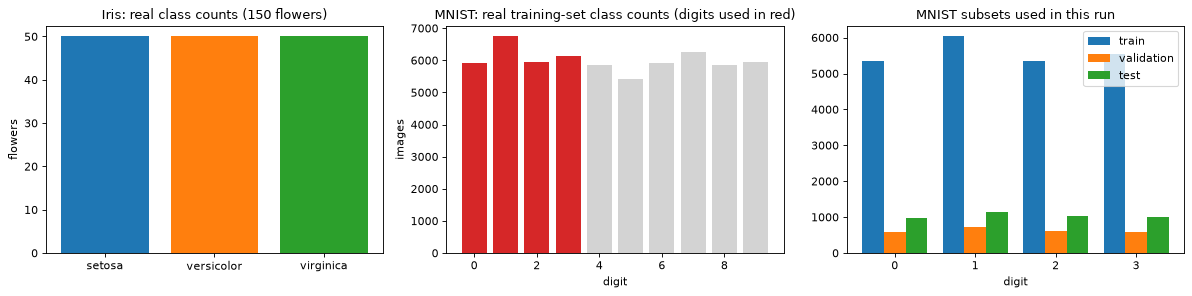

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].bar(IRIS_NAMES, np.bincount(IRIS_y), color=["tab:blue", "tab:orange", "tab:green"]); axs[0].set_title("Iris: real class counts (150 flowers)"); axs[0].set_ylabel("flowers")
cols = ["tab:red" if c in CLASSES else "lightgray" for c in range(10)]
axs[1].bar(range(10), np.bincount(MN["ytrain"], minlength=10), color=cols); axs[1].set_title("MNIST: real training-set class counts (digits used in red)"); axs[1].set_xlabel("digit"); axs[1].set_ylabel("images")
w = 0.27
for off, (lab, y) in enumerate((("train", MS0["ytr"]), ("validation", MS0["yva"]), ("test", MS0["yte"]))):
    axs[2].bar(np.arange(4) + (off - 1) * w, np.bincount(y.numpy(), minlength=4), width=w, label=lab)
axs[2].set_xticks(range(4)); axs[2].set_xticklabels([str(c) for c in CLASSES]); axs[2].set_title("MNIST subsets used in this run"); axs[2].set_xlabel("digit"); axs[2].legend()
plt.tight_layout(); plt.show()

### Example images (real MNIST digits 0 to 3)

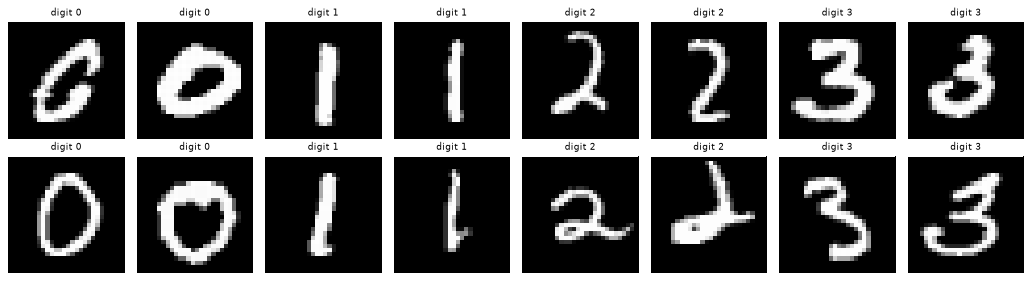

In [7]:
fig, axs = plt.subplots(2, 8, figsize=(13, 3.6))
for c in range(4):
    idx = np.where(MS0["ytr"].numpy() == c)[0][:4]
    for j, i in enumerate(idx):
        ax = axs[j // 2, (c * 2 + j % 2)]; ax.imshow(MS0["Xtr"][i].reshape(28, 28), cmap="gray", vmin=0, vmax=1); ax.set_title(f"digit {CLASSES[c]}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

### 2-D projections of the real observations, coloured by ground-truth label

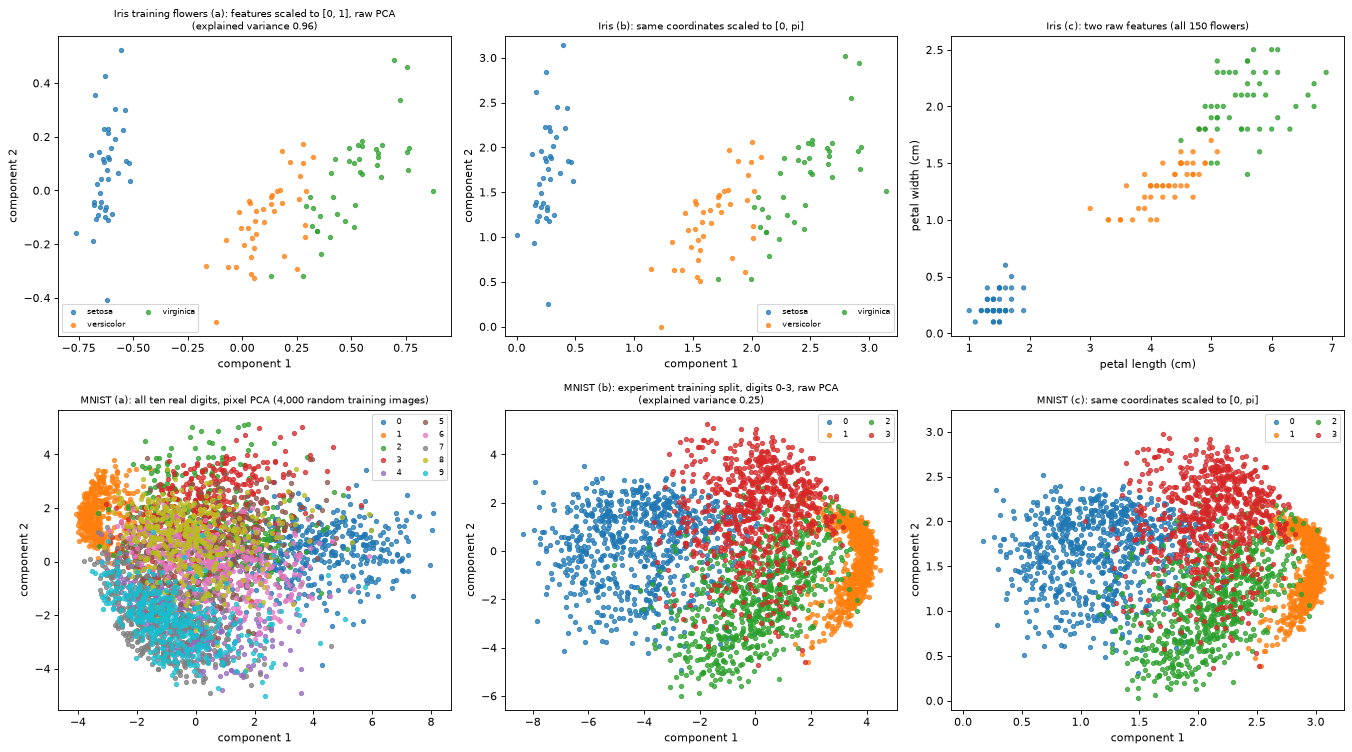

In [8]:
def scatter(ax, Z, y, title, names, cmap="tab10"):
    cm = plt.get_cmap(cmap)
    for k, nm in enumerate(names):
        m = y == k
        if m.any(): ax.scatter(Z[m, 0], Z[m, 1], s=14, color=cm(k if cmap == "tab10" else k), alpha=0.75, label=nm)
    ax.set_title(title, fontsize=9); ax.set_xlabel("component 1"); ax.set_ylabel("component 2"); ax.legend(fontsize=7, ncol=2)

# Iris: stratified split, scaler and PCA fitted on the training split only
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(IRIS_X, IRIS_y, test_size=IRIS_TEST_SIZE, stratify=IRIS_y, random_state=SEED)
sc_i = MinMaxScaler().fit(Xi_tr); pca_i = PCA(2, random_state=SEED).fit(sc_i.transform(Xi_tr)); Zi = pca_i.transform(sc_i.transform(Xi_tr))
sc_ang = MinMaxScaler((0, math.pi)).fit(Zi)
# MNIST: (a) sample of the full file with all ten digits, (b) training split of the experiment (digits 0-3), (c) scaled to [0, pi]
ra = np.random.default_rng(SEED); ids = ra.choice(len(MN["ytrain"]), 4000, replace=False)
Xa, ya = MN["Xtrain"][ids].reshape(4000, -1) / 255.0, MN["ytrain"][ids]
pca_a = PCA(2, random_state=SEED).fit(Xa)
Xt = MS0["Xtr"].numpy(); yt = MS0["ytr"].numpy(); sub = np.random.default_rng(SEED).choice(len(Xt), min(3000, len(Xt)), replace=False)
pca_m = PCA(2, random_state=SEED).fit(Xt); Zm = pca_m.transform(Xt[sub]); sc_m = MinMaxScaler((0, math.pi)).fit(pca_m.transform(Xt))

fig, axs = plt.subplots(2, 3, figsize=(17, 9.5))
scatter(axs[0, 0], Zi, yi_tr, f"Iris training flowers (a): features scaled to [0, 1], raw PCA\n(explained variance {pca_i.explained_variance_ratio_.sum():.2f})", IRIS_NAMES)
scatter(axs[0, 1], sc_ang.transform(Zi), yi_tr, "Iris (b): same coordinates scaled to [0, pi]", IRIS_NAMES)
axs[0, 1].set_xlim(-0.1, math.pi + 0.1); axs[0, 1].set_ylim(-0.1, math.pi + 0.1)
axs[0, 2].scatter(IRIS_X[:, 2], IRIS_X[:, 3], c=[plt.get_cmap("tab10")(k) for k in IRIS_y], s=14, alpha=0.75)
axs[0, 2].set_xlabel(IRIS_FEATS[2]); axs[0, 2].set_ylabel(IRIS_FEATS[3]); axs[0, 2].set_title("Iris (c): two raw features (all 150 flowers)", fontsize=9)
scatter(axs[1, 0], pca_a.transform(Xa), ya, "MNIST (a): all ten real digits, pixel PCA (4,000 random training images)", [str(i) for i in range(10)])
scatter(axs[1, 1], Zm, yt[sub], f"MNIST (b): experiment training split, digits 0-3, raw PCA\n(explained variance {pca_m.explained_variance_ratio_.sum():.2f})", [str(c) for c in CLASSES])
scatter(axs[1, 2], sc_m.transform(pca_m.transform(Xt[sub])), yt[sub], "MNIST (c): same coordinates scaled to [0, pi]", [str(c) for c in CLASSES])
axs[1, 2].set_xlim(-0.1, math.pi + 0.1); axs[1, 2].set_ylim(-0.1, math.pi + 0.1)
plt.tight_layout(); plt.show()

## 2. The quantum network: encoding -> StronglyEntanglingLayers -> measurement

**Circuit (paper Fig. 1 and Fig. 3, right half).** Data encoding $E$, then a parameterised block $U(\theta)$ made of `L` layers of the PennyLane template `StronglyEntanglingLayers`
(a general single-qubit rotation `Rot(phi, theta, omega)` on every qubit, then a ring of CNOT gates whose range grows with the layer index), then $\langle Z\rangle$ on one qubit per class.
The logits are $5\cdot\langle Z_q\rangle$ and the loss is the cross-entropy.

* Iris: 4 qubits, angle encoding `RX(pi x_i)`, 3 layers, 36 parameters, 3 outputs.
* MNIST: 10 qubits, amplitude encoding of the 784 pixels (normalised, zero-padded to 1,024 amplitudes), 4 layers, 120 parameters, 4 outputs.

**Simulation.** FGSM needs the gradient of the loss with respect to the input, so the circuit is simulated exactly **in PyTorch** (state vector, 64-bit capable): each layer is the Kronecker product of the single-qubit `Rot` matrices
(applied as $K_a\,S\,K_b^{T}$ on the state reshaped to a matrix) followed by the index permutation of the CNOT ring. The next section draws the **real PennyLane QNode** and asserts that both give the same $\langle Z_q\rangle$ to 1e-9 on real data.

**Classical counterpart.** A small MLP (ReLU) takes the same inputs (with or without the same frozen DAE) and is trained, attacked and adversarially trained in exactly the same way.

In [9]:
# ================= exact differentiable state-vector simulator of the StronglyEntanglingLayers circuit =================
def sel_ranges(L, n):
    return [(l % (n - 1)) + 1 for l in range(L)]          # PennyLane default ranges of StronglyEntanglingLayers

def cnot_perm(n, pairs):
    perm = np.arange(2 ** n)                              # qubit 0 = most significant bit (PennyLane convention)
    for c, t in pairs:
        cbit = (perm >> (n - 1 - c)) & 1
        perm = np.where(cbit == 1, perm ^ (1 << (n - 1 - t)), perm)
    return perm                                           # new_state[perm[i]] = old_state[i]

class Sim:
    def __init__(self, n, L, k):
        self.n, self.L, self.k = n, L, k
        self.inv = [torch.tensor(np.argsort(cnot_perm(n, [(i, (i + r) % n) for i in range(n)]))) for r in sel_ranges(L, n)]
        self.Z = torch.tensor([[1.0 - 2.0 * ((i >> (n - 1 - q)) & 1) for q in range(k)] for i in range(2 ** n)])   # eigenvalue of Z_q on basis state i

    @staticmethod
    def rot_mats(w):                                      # w (..., 3) = (phi, theta, omega) -> Rot(phi, theta, omega) as (..., 2, 2)
        phi, th, om = w[..., 0], w[..., 1], w[..., 2]
        c, s = torch.cos(th / 2), torch.sin(th / 2)
        cd = torch.complex(c, torch.zeros_like(c)).dtype
        a = torch.exp(-0.5j * (phi + om).to(cd)) * c
        b = -torch.exp(0.5j * (phi - om).to(cd)) * s
        cc = torch.exp(-0.5j * (phi - om).to(cd)) * s
        d = torch.exp(0.5j * (phi + om).to(cd)) * c
        return torch.stack([torch.stack([a, b], -1), torch.stack([cc, d], -1)], -2)

    def run(self, state, W):
        # state (B, 2^n) complex, W (L, n, 3) -> <Z_q> for q < k, shape (B, k)
        n = self.n; h = n // 2; B = state.shape[0]
        U = self.rot_mats(W); st = state.reshape(B, -1)
        for l in range(self.L):
            Ka = U[l, 0]
            for q in range(1, h): Ka = torch.kron(Ka, U[l, q])
            Kb = U[l, h]
            for q in range(h + 1, n): Kb = torch.kron(Kb, U[l, q])
            st = (Ka @ st.reshape(B, 2 ** h, 2 ** (n - h)) @ Kb.T).reshape(B, -1)[:, self.inv[l]]      # Rot layer, then CNOT ring
        return (st.abs() ** 2) @ self.Z.to(st.real.dtype)

def _cdt(x): return torch.complex64 if x.dtype == torch.float32 else torch.complex128

def encode_amp(x, n=N_QUBITS_M):
    # amplitude encoding: pad to 2^n amplitudes and normalise (qml.AmplitudeEmbedding(pad_with=0, normalize=True))
    xp = F.pad(x, (0, 2 ** n - x.shape[1]))
    return (xp / (xp.norm(dim=1, keepdim=True) + 1e-12)).to(_cdt(x))

def encode_angle(x):
    # angle encoding: RX(pi * x_i)|0> = cos(a/2)|0> - i sin(a/2)|1>, product state over the qubits (qml.AngleEmbedding(rotation="X"))
    a = math.pi * x; cd = _cdt(x)
    v = torch.stack([torch.cos(a / 2).to(cd), -1j * torch.sin(a / 2).to(cd)], -1)      # (B, n, 2)
    st = v[:, 0]
    for q in range(1, x.shape[1]): st = (st[:, :, None] * v[:, q][:, None, :]).reshape(x.shape[0], -1)
    return st

class QNet(nn.Module):
    # hybrid network: [frozen DAE pre-encoding layer] -> encoding -> StronglyEntanglingLayers -> <Z> -> logits
    def __init__(self, sim, encode, dae=None, init_std=0.1):
        super().__init__()
        self.sim, self.encode, self.dae = sim, encode, dae
        self.W = nn.Parameter(torch.randn(sim.L, sim.n, 3) * init_std)             # CHOICE: small random initial angles
    def forward(self, x):
        if self.dae is not None: x = self.dae(x)
        return LOGIT_SCALE * self.sim.run(self.encode(x), self.W)

class MLP(nn.Module):
    # classical counterpart on identical inputs
    def __init__(self, d_in, hidden, k, dae=None):
        super().__init__()
        self.dae = dae; self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(), nn.Linear(hidden, k))
    def forward(self, x):
        if self.dae is not None: x = self.dae(x)
        return self.net(x)

class DAE(nn.Module):
    # denoising autoencoder = the pre-encoding / preprocessing layer; dims e.g. [784, 256, 64, 256, 784]
    def __init__(self, dims, sigmoid):
        super().__init__()
        layers = []
        for i in range(len(dims) - 1):
            layers.append(nn.Linear(dims[i], dims[i + 1]))
            if i < len(dims) - 2: layers.append(nn.ReLU())
        if sigmoid: layers.append(nn.Sigmoid())
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

SIM_IRIS = Sim(4, IRIS_LAYERS, 3)
SIM_MNIST = Sim(N_QUBITS_M, M_LAYERS, len(CLASSES))
print("Iris circuit : %d qubits, %d layers, %d trainable parameters, ranges %s" % (SIM_IRIS.n, SIM_IRIS.L, SIM_IRIS.L * SIM_IRIS.n * 3, sel_ranges(SIM_IRIS.L, 4)))
print("MNIST circuit: %d qubits, %d layers, %d trainable parameters, ranges %s" % (SIM_MNIST.n, SIM_MNIST.L, SIM_MNIST.L * SIM_MNIST.n * 3, sel_ranges(SIM_MNIST.L, N_QUBITS_M)))

Iris circuit : 4 qubits, 3 layers, 36 trainable parameters, ranges [1, 2, 3]
MNIST circuit: 10 qubits, 4 layers, 120 trainable parameters, ranges [1, 2, 3, 4]


## Quantum Circuit Architecture

The drawings are made by `qml.draw_mpl` from the **real PennyLane QNodes** (`default.qubit`, exact analytic expectation values). For each of the two architectures the paper's pipeline needs, the cell:

1. draws the QNode as written (embedding + `StronglyEntanglingLayers` block + measurements) and, below it, the same circuit expanded to the gates the device executes (`Rot` and `CNOT`);
2. prints qubit count, circuit depth, gate counts and the number of trainable parameters;
3. **asserts** that the PyTorch simulator used for training and for the FGSM gradients gives the same $\langle Z_q\rangle$ as the PennyLane QNode (maximum difference < 1e-9, 64-bit) on **real** Iris flowers and real MNIST test images, with random circuit angles. The assertion is repeated with trained weights in Section 5.

There are two architectures (Iris: 4 qubits with angle encoding; MNIST: 10 qubits with amplitude encoding); the paper itself gives no circuit details, so the choices are the ones in the table above. The DAE is classical and not part of the circuit
(its output is what enters the encoding stage). The classical MLP counterpart has no circuit.

max |PyTorch simulator - PennyLane QNode|: Iris (real flowers) 2.78e-16 | MNIST (real test images) 2.12e-14   (assertion < 1e-9 passed)


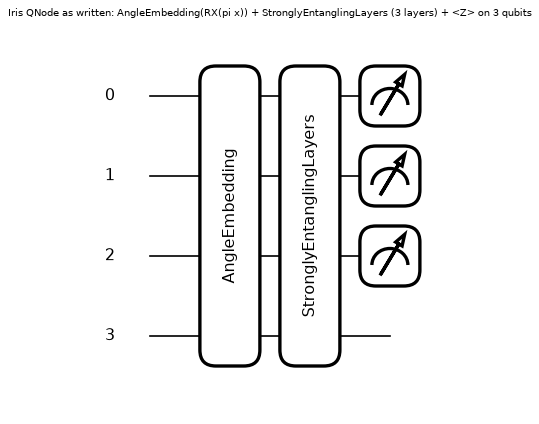

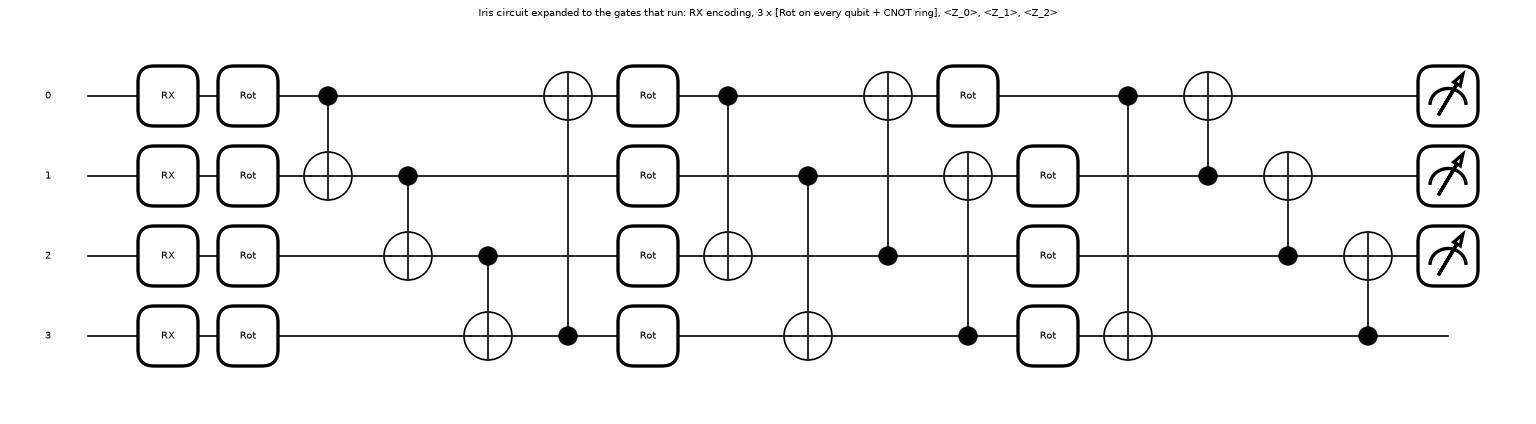

Iris : qubits = 4 | circuit depth (device level) = 14 | gates = 28 {'RX': 4, 'Rot': 12, 'CNOT': 12} | trainable parameters = 36 (3 layers x 4 qubits x 3 Rot angles)


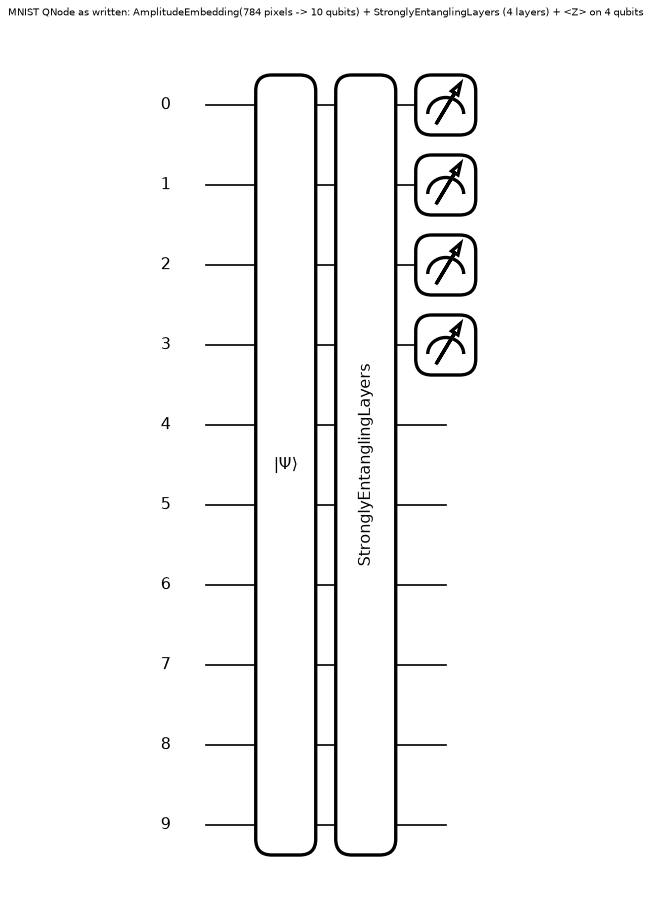

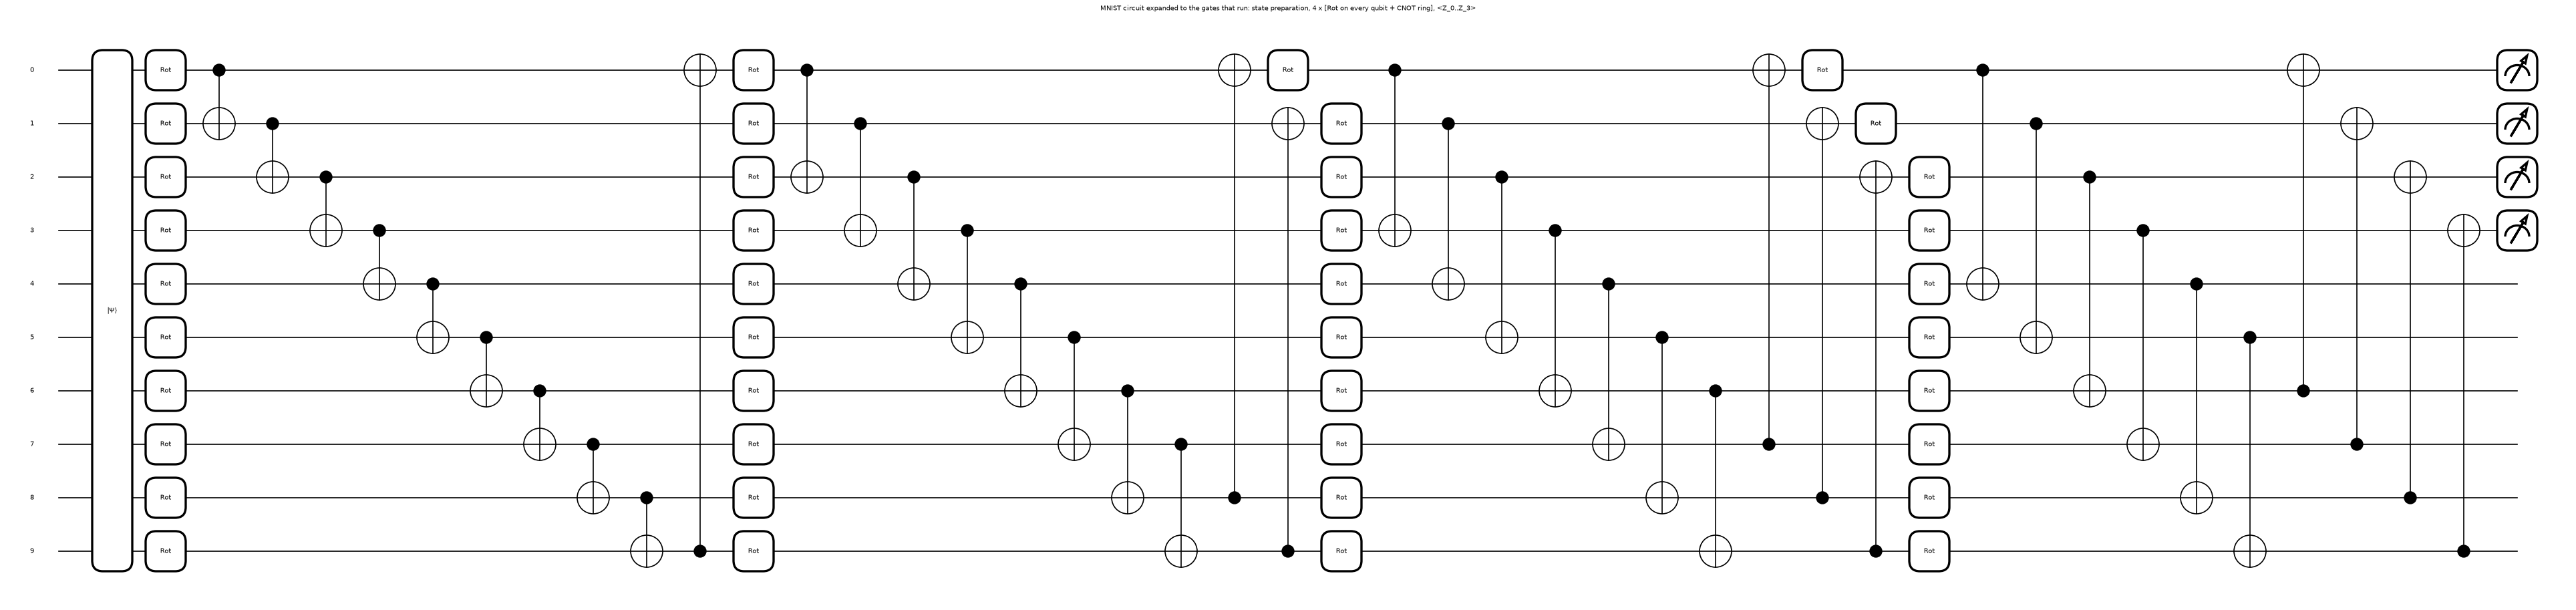

MNIST: qubits = 10 | circuit depth (device level) = 26 | gates = 81 {'AmplitudeEmbedding': 1, 'Rot': 40, 'CNOT': 40} | trainable parameters = 120 (4 layers x 10 qubits x 3 Rot angles)


In [10]:
# ---- the real PennyLane QNodes ----
def make_qnode(kind, n, k):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch")
    def circ(x, w):
        if kind == "amp":
            qml.AmplitudeEmbedding(x, wires=range(n), pad_with=0.0, normalize=True)
        else:
            qml.AngleEmbedding(math.pi * x, wires=range(n), rotation="X")
        qml.StronglyEntanglingLayers(w, wires=range(n))
        return [qml.expval(qml.Z(q)) for q in range(k)]
    return circ

QN_IRIS  = make_qnode("angle", 4, 3)
QN_MNIST = make_qnode("amp", N_QUBITS_M, len(CLASSES))

def check_equivalence(sim, qnode, encode, W, X, k=6):
    # assert: PyTorch simulator == PennyLane QNode on k real inputs, in float64
    Xd, Wd = X[:k].double(), W.detach().double()
    with torch.no_grad():
        mine = sim.run(encode(Xd), Wd)
        ref = torch.stack([torch.stack(qnode(Xd[i], Wd)) for i in range(Xd.shape[0])])
    diff = (mine - ref).abs().max().item()
    assert diff < 1e-9, f"simulator and QNode differ by {diff}"
    return diff

g0 = torch.Generator().manual_seed(SEED)
Wi0 = torch.rand(IRIS_LAYERS, 4, 3, generator=g0) * 2 * math.pi            # random angles: a much harder test than the small initial angles
Wm0 = torch.rand(M_LAYERS, N_QUBITS_M, 3, generator=g0) * 2 * math.pi
Xi_real = torch.tensor(sc_i.transform(Xi_te), dtype=torch.float32)          # real Iris test flowers scaled to [0, 1]
d_i = check_equivalence(SIM_IRIS, QN_IRIS, encode_angle, Wi0, Xi_real)
d_m = check_equivalence(SIM_MNIST, QN_MNIST, encode_amp, Wm0, MS0["Xte"])
print("max |PyTorch simulator - PennyLane QNode|: Iris (real flowers) %.2e | MNIST (real test images) %.2e   (assertion < 1e-9 passed)" % (d_i, d_m))

def describe(name, qnode, x, W, n, L):
    sp = qml.specs(qnode, level="device")(x, W); res = sp["resources"]
    print(f"{name}: qubits = {res.num_allocs} | circuit depth (device level) = {res.depth} | gates = {res.num_gates} {dict(res.gate_types)} | "
          f"trainable parameters = {L * n * 3} ({L} layers x {n} qubits x 3 Rot angles)")

# ---- Iris circuit: compact and expanded ----
xi, Wi = Xi_real[0].double(), Wi0.double()
fig, ax = qml.draw_mpl(QN_IRIS, level="gradient", decimals=None)(xi, Wi); fig.suptitle("Iris QNode as written: AngleEmbedding(RX(pi x)) + StronglyEntanglingLayers (3 layers) + <Z> on 3 qubits", y=1.02, fontsize=9); plt.show()
fig, ax = qml.draw_mpl(QN_IRIS, level="device", decimals=None, fontsize=9)(xi, Wi); fig.suptitle("Iris circuit expanded to the gates that run: RX encoding, 3 x [Rot on every qubit + CNOT ring], <Z_0>, <Z_1>, <Z_2>", y=1.02, fontsize=9); plt.show()
describe("Iris ", QN_IRIS, xi, Wi, 4, IRIS_LAYERS)

# ---- MNIST circuit: compact and expanded ----
xm, Wm = MS0["Xte"][0].double(), Wm0.double()
fig, ax = qml.draw_mpl(QN_MNIST, level="gradient", decimals=None)(xm, Wm); fig.suptitle("MNIST QNode as written: AmplitudeEmbedding(784 pixels -> 10 qubits) + StronglyEntanglingLayers (4 layers) + <Z> on 4 qubits", y=1.02, fontsize=9); plt.show()
fig, ax = qml.draw_mpl(QN_MNIST, level="device", decimals=None, fontsize=9)(xm, Wm); fig.suptitle("MNIST circuit expanded to the gates that run: state preparation, 4 x [Rot on every qubit + CNOT ring], <Z_0..Z_3>", y=1.02, fontsize=9); plt.show()
describe("MNIST", QN_MNIST, xm, Wm, N_QUBITS_M, M_LAYERS)

## 3. Pre-encoding layer (denoising autoencoder), FGSM, metrics

* **DAE.** Trained first, on the training split only, to map Gaussian-noisy inputs to the clean inputs (MSE loss, Adam); afterwards frozen. It is placed in front of the encoding stage of the QNN. The QNN with the layer is trained on the DAE outputs of the clean training data (only the circuit angles are learned).
* **FGSM (Eq. 4).** $x_{adv} = x + \epsilon\,\mathrm{sign}(\nabla_x J)$ with $J$ the cross-entropy of the attacked model. **Static** attack: the gradient comes from the plain QNN (the paper's pipeline of Fig. 6). **Adaptive** attack: the gradient comes from the attacked model itself, including the DAE.
* **Similarity metrics (Eqs. 2, 3).** Mean squared error and mean per-sample cosine similarity to the original data.

In [11]:
def evaluate(model, X, y, bs=1000):
    model.eval(); hit = 0; nll = 0.0
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out = model(X[i:i + bs]); hit += (out.argmax(1) == y[i:i + bs]).sum().item(); nll += F.cross_entropy(out, y[i:i + bs], reduction="sum").item()
    return 100.0 * hit / len(X), nll / len(X)

def fgsm(model, X, y, eps, clip=None, bs=1000, scale=None):
    # Eq. 4: x_adv = x + eps * sign(grad_x J(theta, x, y)); clip=(lo, hi) keeps pixels valid (MNIST), None for Iris (Eq. 4 has no clip)
    # scale: optional per-feature step multiplier (used only for the Iris sensitivity study with epsilon in standard-deviation units)
    model.eval(); outs = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].clone().requires_grad_(True)
        g, = torch.autograd.grad(F.cross_entropy(model(x), y[i:i + bs], reduction="sum"), x)
        xa = x.detach() + eps * (g.sign() if scale is None else g.sign() * scale)
        outs.append(xa.clamp(*clip) if clip else xa)
    return torch.cat(outs)

def fit(model, X, y, Xv, yv, epochs, lr, bs, seed, tag=""):
    # Adam on the trainable parameters; with a validation set the epoch with the lowest validation loss is kept (never the test set)
    g = torch.Generator().manual_seed(seed)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=lr); best, snap, hist = 1e18, None, []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X), generator=g); tl = 0.0; hit = 0
        for i in range(0, len(X), bs):
            b = perm[i:i + bs]; out = model(X[b]); loss = F.cross_entropy(out, y[b])
            opt.zero_grad(); loss.backward(); opt.step(); tl += loss.item() * len(b); hit += (out.argmax(1) == y[b]).sum().item()
        row = dict(epoch=ep + 1, train_loss=tl / len(X), train_acc=100.0 * hit / len(X))
        if Xv is not None:
            va, vl = evaluate(model, Xv, yv); row.update(val_loss=vl, val_acc=va)
            if vl < best: best, snap = vl, [p.detach().clone() for p in params]
        hist.append(row)
    if snap is not None:
        with torch.no_grad():
            for p, s in zip(params, snap): p.copy_(s)
    model.eval()
    return pd.DataFrame(hist)

def train_dae(X, dims, sigma, epochs, lr, bs, seed, sigmoid, clip01):
    torch.manual_seed(seed); dae = DAE(dims, sigmoid); opt = torch.optim.Adam(dae.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), bs):
            x = X[perm[i:i + bs]]; xn = x + sigma * torch.randn(x.shape, generator=g)
            if clip01: xn = xn.clamp(0, 1)
            loss = F.mse_loss(dae(xn), x); opt.zero_grad(); loss.backward(); opt.step()
    for p in dae.parameters(): p.requires_grad_(False)
    return dae.eval()

def mse_cos(a, ref):
    # Eq. 2 (mean over all entries) and Eq. 3 (mean over samples) between a and the original data ref
    return F.mse_loss(a, ref).item(), F.cosine_similarity(a, ref, dim=1).mean().item()

def noisy(X, sigma, seed, clip01):
    g = torch.Generator().manual_seed(seed); xn = X + sigma * torch.randn(X.shape, generator=g)
    return xn.clamp(0, 1) if clip01 else xn

## 4. Iris: Table 1 and Fig. 4

For each seed: stratified 80/20 split, features scaled to $[0, 1]$ (scaler fitted on the training flowers), DAE `4-16-2-16-4`, plain QNN and QNN with the DAE (4 qubits), plain MLP and MLP with the DAE. Then:

* **Table 1**: MSE and cosine similarity of (a) Gaussian-noisy test data and (b) FGSM test data (epsilon `IRIS_T1_EPS`, crafted against the plain QNN) to the original test data, before and after the DAE.
* **Fig. 4**: accuracy on the FGSM test data at epsilon 0.15 / 0.30 / 0.45 / 0.60 with and without the layer (static attack, plus the adaptive attack as an extra).

**Units of epsilon (a sensitivity study added after the first run).** The paper does not say how the Iris features were scaled, so "epsilon 0.15" is ambiguous. The **main reading** (fixed in advance) is epsilon in the units of the $[0, 1]$-scaled features.
After seeing that this reading is a much stronger attack than the paper's accuracies suggest, a second reading was added: epsilon in **standard-deviation units** (feature $j$ moves by $\epsilon\cdot\sigma_j$ with $\sigma_j$ the training standard deviation, about 0.2 to 0.3 in $[0, 1]$ units, so the same epsilon is 3 to 5 times weaker).
It is reported separately and never replaces the main reading; the diagnostic after Table 1 shows what data norm the paper's cosine similarities imply.

In [12]:
IRIS_ROWS, IRIS_REC = [], []

def run_iris(seed):
    Xtr, Xte, ytr, yte = train_test_split(IRIS_X, IRIS_y, test_size=IRIS_TEST_SIZE, stratify=IRIS_y, random_state=seed)
    sc = MinMaxScaler().fit(Xtr)                                              # fitted on the training flowers only
    Xtr, Xte = [torch.tensor(sc.transform(a), dtype=torch.float32) for a in (Xtr, Xte)]; ytr, yte = torch.tensor(ytr), torch.tensor(yte)
    dae = train_dae(Xtr, [4, 16, 2, 16, 4], IRIS_SIGMA, IRIS_DAE_EPOCHS, IRIS_DAE_LR, len(Xtr), seed, sigmoid=False, clip01=False)   # CHOICE: bottleneck of 2 (Iris is nearly 2-D)
    models = {}
    for name, mk in (("QNN", lambda: QNet(SIM_IRIS, encode_angle)), ("QNN+DAE", lambda: QNet(SIM_IRIS, encode_angle, dae)),
                     ("MLP", lambda: MLP(4, 8, 3)), ("MLP+DAE", lambda: MLP(4, 8, 3, dae))):
        torch.manual_seed(seed); m = mk()
        fit(m, Xtr, ytr, None, None, IRIS_EPOCHS, IRIS_LR, len(Xtr), seed); models[name] = m
    for name, m in models.items():
        IRIS_ROWS.append(dict(seed=seed, model=name, units="-", mode="clean", eps=0.0, acc=evaluate(m, Xte, yte)[0]))
        IRIS_ROWS.append(dict(seed=seed, model=name, units="-", mode="gaussian noise", eps=IRIS_SIGMA, acc=evaluate(m, noisy(Xte, IRIS_SIGMA, seed, False), yte)[0]))
    zstd = Xtr.std(0)                                                         # per-feature standard deviation of the training flowers (features in [0, 1])
    # main reading: epsilon in the units of the [0, 1]-scaled features. Sensitivity study (added after seeing the first results, see the text):
    # epsilon in standard-deviation (z-score) units, i.e. the step of feature j is eps * std_j, because the paper does not say how Iris was scaled
    for units, scale in (("[0,1] units", None), ("z-score units", zstd)):
        for eps in IRIS_EPS:
            for src, grp in (("QNN", ("QNN", "QNN+DAE")), ("MLP", ("MLP", "MLP+DAE"))):
                Xadv = fgsm(models[src], Xte, yte, eps, scale=scale)          # crafted against the plain model
                for name in grp:
                    IRIS_ROWS.append(dict(seed=seed, model=name, units=units, mode="static", eps=eps, acc=evaluate(models[name], Xadv, yte)[0]))
                    IRIS_ROWS.append(dict(seed=seed, model=name, units=units, mode="adaptive", eps=eps, acc=evaluate(models[name], fgsm(models[name], Xte, yte, eps, scale=scale), yte)[0]))
    # Table 1: similarity to the original test data
    ref = Xte; Xn = noisy(Xte, IRIS_SIGMA, seed, False); Xf = fgsm(models["QNN"], Xte, yte, IRIS_T1_EPS)
    with torch.no_grad():
        for lab, a in (("noisy", Xn), ("fgsm", Xf)):
            for stage, z in (("before", a), ("after", dae(a))):
                mse, cs = mse_cos(z, ref); IRIS_REC.append(dict(seed=seed, data=lab, stage=stage, mse=mse, cos=cs))
    return models, dae, Xtr, Xte, ytr, yte

t_iris = time.time()
for s in range(IRIS_SEEDS):
    out = run_iris(SEED + s)
    if s == 0: IRIS0 = out
    print(f"Iris seed {SEED + s}: clean accuracy " + ", ".join(f"{r['model']} {r['acc']:.1f}" for r in IRIS_ROWS if r['seed'] == SEED + s and r['mode'] == 'clean'), flush=True)
IR = pd.DataFrame(IRIS_ROWS); IREC = pd.DataFrame(IRIS_REC)
print("Iris finished in %.1f s" % (time.time() - t_iris))

Iris seed 42: clean accuracy QNN 93.3, QNN+DAE 86.7, MLP 100.0, MLP+DAE 90.0


Iris seed 43: clean accuracy QNN 96.7, QNN+DAE 96.7, MLP 96.7, MLP+DAE 96.7


Iris seed 44: clean accuracy QNN 96.7, QNN+DAE 96.7, MLP 100.0, MLP+DAE 96.7


Iris seed 45: clean accuracy QNN 90.0, QNN+DAE 86.7, MLP 90.0, MLP+DAE 80.0


Iris seed 46: clean accuracy QNN 96.7, QNN+DAE 93.3, MLP 93.3, MLP+DAE 96.7


...

Iris seed 58: clean accuracy QNN 93.3, QNN+DAE 93.3, MLP 93.3, MLP+DAE 93.3


Iris seed 59: clean accuracy QNN 93.3, QNN+DAE 90.0, MLP 96.7, MLP+DAE 93.3


Iris seed 60: clean accuracy QNN 90.0, QNN+DAE 90.0, MLP 93.3, MLP+DAE 90.0


Iris seed 61: clean accuracy QNN 96.7, QNN+DAE 93.3, MLP 100.0, MLP+DAE 96.7


Iris finished in 190.1 s


In [13]:
# ---- Table 1 re-drawn (mean +- std over seeds) ----
t1 = IREC.groupby(["data", "stage"])[["mse", "cos"]].agg(["mean", "std"]).round(3)
display(t1)
PAPER_T1 = {("noisy", "before"): (0.263, 0.832), ("noisy", "after"): (0.173, 0.895), ("fgsm", "before"): (0.211, 0.873), ("fgsm", "after"): (0.176, 0.910)}
tab1 = pd.DataFrame([dict(data=d, stage=s, mse_paper=p[0], mse_notebook=IREC[(IREC.data == d) & (IREC.stage == s)].mse.mean(),
                          cos_paper=p[1], cos_notebook=IREC[(IREC.data == d) & (IREC.stage == s)].cos.mean()) for (d, s), p in PAPER_T1.items()]).round(3)
display(tab1.set_index(["data", "stage"]))
# Diagnostic: how large is the original data vector in the paper's setting? With d = 4 features, the noise vector has norm sqrt(4 * MSE) and
# cosine = |x| / sqrt(|x|^2 + |noise|^2) for noise orthogonal to x, so |x| = |noise| / tan(arccos(cos)). Compare with the norm of our [0, 1] data.
nrm = float(IRIS0[3].norm(dim=1).mean())
imp = {k: math.sqrt(4 * p[0]) / math.tan(math.acos(p[1])) for k, p in PAPER_T1.items() if k[1] == "before"}
print("mean norm of our [0, 1]-scaled Iris test flowers: %.2f" % nrm)
print("norm of the original data implied by the paper's 'before' rows (noise orthogonal to x): " + ", ".join(f"{k[0]} {v:.2f}" for k, v in imp.items()))

mse           cos       
               mean    std   mean    std
data  stage                             
fgsm  after   0.075  0.014  0.870  0.027
      before  0.203  0.000  0.668  0.041
noisy after   0.045  0.015  0.924  0.028
      before  0.256  0.032  0.690  0.048

mse_paper  mse_notebook  cos_paper  cos_notebook
data  stage                                                   
noisy before      0.263         0.256      0.832         0.690
      after       0.173         0.045      0.895         0.924
fgsm  before      0.211         0.203      0.873         0.668
      after       0.176         0.075      0.910         0.870

mean norm of our [0, 1]-scaled Iris test flowers: 0.98
norm of the original data implied by the paper's 'before' rows (noise orthogonal to x): noisy 1.54, fgsm 1.64


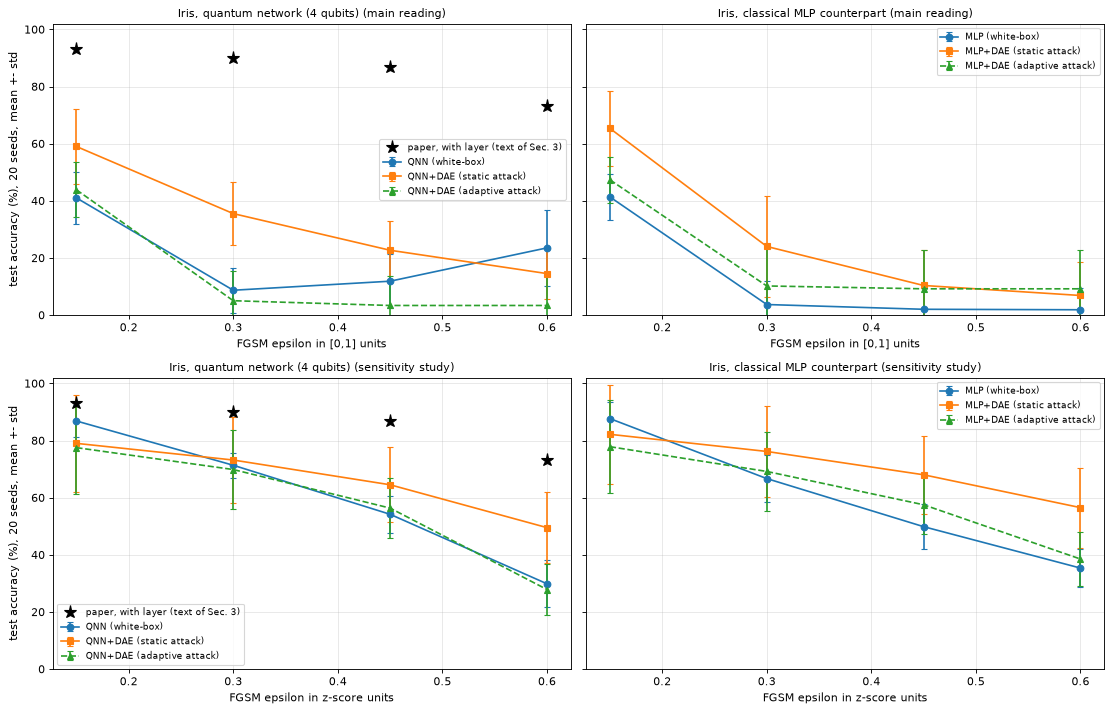

eps                                   0.00  0.15  0.30  0.45  0.50  0.60
model   units         mode                                              
MLP     -             clean           96.8   NaN   NaN   NaN   NaN   NaN
                      gaussian noise   NaN   NaN   NaN   NaN  58.5   NaN
        [0,1] units   adaptive         NaN  41.3   3.7   2.0   NaN   1.8
                      static           NaN  41.3   3.7   2.0   NaN   1.8
        z-score units adaptive         NaN  87.7  66.7  49.8   NaN  35.3
                      static           NaN  87.7  66.7  49.8   NaN  35.3
MLP+DAE -             clean           86.7   NaN   NaN   NaN   NaN   NaN
                      gaussian noise   NaN   NaN   NaN   NaN  56.2   NaN
        [0,1] units   adaptive         NaN  47.3  10.2   9.2   NaN   9.2
                      static           NaN  65.3  24.0  10.3   NaN   6.8
        z-score units adaptive         NaN  77.8  69.2  57.5   NaN  38.5
                      static           NaN  82.2  76.2  68.0   NaN  56.5
QNN     -             clean           95.3   NaN   NaN   NaN   NaN   NaN
                      gaussian noise   NaN   NaN   NaN   NaN  42.7   NaN
        [0,1] units   adaptive         NaN  41.0   8.7  11.8   NaN  23.5
                      static           NaN  41.0   8.7  11.8   NaN  23.5
        z-score units adaptive         NaN  86.8  71.3  54.2   NaN  29.8
                      static           NaN  86.8  71.3  54.2   NaN  29.8
QNN+DAE -             clean           86.3   NaN   NaN   NaN   NaN   NaN
                      gaussian noise   NaN   NaN   NaN   NaN  56.0   NaN
        [0,1] units   adaptive         NaN  43.8   5.0   3.3   NaN   3.3
                      static           NaN  59.0  35.5  22.7   NaN  14.5
        z-score units adaptive         NaN  77.5  69.8  56.3   NaN  27.8
                      static           NaN  79.0  73.2  64.5   NaN  49.5

In [14]:
# ---- Fig. 4 re-drawn: accuracy under FGSM with and without the pre-encoding layer ----
def agg(df, **flt):
    d = df
    for k, v in flt.items(): d = d[d[k] == v]
    return d.groupby(["model", "units", "mode", "eps"]).acc.agg(["mean", "std", "min", "max"]).reset_index()

UNITS = ("[0,1] units", "z-score units")
fig, axs = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
for r_, units in enumerate(UNITS):
    for ax, grp, title in ((axs[r_, 0], ("QNN", "QNN+DAE"), "quantum network (4 qubits)"), (axs[r_, 1], ("MLP", "MLP+DAE"), "classical MLP counterpart")):
        for name, st, mode in ((grp[0], "o-", "static"), (grp[1], "s-", "static"), (grp[1], "^--", "adaptive")):
            a = agg(IR, model=name, mode=mode, units=units); a = a[a.eps.isin(IRIS_EPS)].sort_values("eps")
            ax.errorbar(a.eps, a["mean"], yerr=a["std"].fillna(0), fmt=st, capsize=3, label=f"{name} ({mode} attack)" if name != grp[0] else f"{name} (white-box)")
        if grp[0] == "QNN":
            ax.plot(IRIS_EPS, [93.3, 90.0, 86.67, 73.33], "k*", ms=12, label="paper, with layer (text of Sec. 3)")
        ax.set_xlabel("FGSM epsilon in " + units); ax.set_title("Iris, " + title + (" (main reading)" if r_ == 0 else " (sensitivity study)"), fontsize=10); ax.grid(alpha=0.3); ax.legend(fontsize=8); ax.set_ylim(0, 102)
    axs[r_, 0].set_ylabel("test accuracy (%%), %d seeds, mean +- std" % IRIS_SEEDS)
plt.tight_layout(); plt.show()
IRm = IR[IR.units.isin(["[0,1] units", "-"])]; IRz = IR[IR.units.isin(["z-score units", "-"])]     # main reading and z-score sensitivity study
display(agg(IR).pivot_table(index=["model", "units", "mode"], columns="eps", values="mean").round(1))

## 5. 4-class MNIST: Fig. 5, Fig. 6 and Table 2

For each seed: DAE `784-256-64-256-784` (trained on the Gaussian-noisy -> clean training images), then six networks on identical inputs.

| name | what it is |
|---|---|
| `QNN` | 10-qubit amplitude-encoded QNN on the raw pixels (paper: "non-preproc") |
| `QNN+DAE` | the same circuit behind the frozen DAE (paper: "preproc") |
| `QNN adv-trained` | fresh QNN trained on the clean training images plus FGSM images of the plain QNN at eps 0.15 / 0.30 / 0.45 (paper: "adv-training") |
| `MLP`, `MLP+DAE`, `MLP adv-trained` | the classical counterpart, handled identically |

For every epsilon the **static** adversarial test set (FGSM against the plain network of the same family) is evaluated on all three networks of that family; the **adaptive** attack differentiates through each network itself.

In [15]:
MN_ROWS, MN_REC, MN_HIST, MN_TIME = [], [], {}, []

def run_mnist(seed):
    d = mnist_split(seed); Xtr, ytr, Xva, yva, Xte, yte = (d[k] for k in ("Xtr", "ytr", "Xva", "yva", "Xte", "yte"))
    K = len(CLASSES); t0 = time.time()
    dae = train_dae(Xtr, [784, 256, 64, 256, 784], DAE_SIGMA, DAE_EPOCHS, DAE_LR, BATCH, seed, sigmoid=True, clip01=True); t_dae = time.time() - t0
    r = np.random.default_rng(seed + 1)
    def advset(src, eps_list):
        # CHOICE: ADV_FRACTION * |train| adversarial images (one third per epsilon) crafted against the plain model, plus a small adversarial validation set
        n_adv = int(round(ADV_FRACTION * len(Xtr))); n_va = max(3, int(round(ADV_FRACTION * len(Xva))))
        idx = r.permutation(len(Xtr))[:n_adv]; vidx = r.permutation(len(Xva))[:n_va]
        parts = np.array_split(idx, len(eps_list)); vparts = np.array_split(vidx, len(eps_list))
        Xa = torch.cat([fgsm(src, Xtr[p], ytr[p], e, (0, 1)) for p, e in zip(parts, eps_list)]); ya = torch.cat([ytr[p] for p in parts])
        Xva_a = torch.cat([fgsm(src, Xva[p], yva[p], e, (0, 1)) for p, e in zip(vparts, eps_list)]); yva_a = torch.cat([yva[p] for p in vparts])
        return Xa, ya, Xva_a, yva_a
    nets, hist, times = {}, {}, {"DAE": t_dae}
    for fam, mk, lr in (("QNN", lambda dae_=None: QNet(SIM_MNIST, encode_amp, dae_), QNN_LR), ("MLP", lambda dae_=None: MLP(784, 64, K, dae_), 1e-3)):
        t1 = time.time(); torch.manual_seed(seed); a = mk(); hist[fam] = fit(a, Xtr, ytr, Xva, yva, EPOCHS, lr, BATCH, seed); times[fam + " plain"] = time.time() - t1
        t1 = time.time(); torch.manual_seed(seed); b = mk(dae); hist[fam + "+DAE"] = fit(b, Xtr, ytr, Xva, yva, EPOCHS, lr, BATCH, seed); times[fam + "+DAE"] = time.time() - t1
        t1 = time.time(); Xa, ya, Xv2, yv2 = advset(a, MNIST_EPS)
        torch.manual_seed(seed); c = mk(); hist[fam + " adv-trained"] = fit(c, torch.cat([Xtr, Xa]), torch.cat([ytr, ya]), torch.cat([Xva, Xv2]), torch.cat([yva, yv2]), EPOCHS, lr, BATCH, seed)
        times[fam + " adv-trained (incl. FGSM generation)"] = time.time() - t1
        nets[fam] = a; nets[fam + "+DAE"] = b; nets[fam + " adv-trained"] = c
    for name, m in nets.items():
        MN_ROWS.append(dict(seed=seed, model=name, mode="clean", eps=0.0, acc=evaluate(m, Xte, yte)[0]))
        MN_ROWS.append(dict(seed=seed, model=name, mode="gaussian noise", eps=DAE_SIGMA, acc=evaluate(m, noisy(Xte, DAE_SIGMA, seed, True), yte)[0]))
    for eps in MNIST_EPS:
        for fam in ("QNN", "MLP"):
            Xadv = fgsm(nets[fam], Xte, yte, eps, (0, 1))                       # static: crafted against the plain model of the family
            for name in (fam, fam + "+DAE", fam + " adv-trained"):
                MN_ROWS.append(dict(seed=seed, model=name, mode="static", eps=eps, acc=evaluate(nets[name], Xadv, yte)[0]))
                MN_ROWS.append(dict(seed=seed, model=name, mode="adaptive", eps=eps, acc=evaluate(nets[name], fgsm(nets[name], Xte, yte, eps, (0, 1)), yte)[0]))
    Xn = noisy(Xte, DAE_SIGMA, seed, True); Xf = {e: fgsm(nets["QNN"], Xte, yte, e, (0, 1)) for e in MNIST_EPS}
    with torch.no_grad():
        for lab, a_ in [("noisy", Xn)] + [(f"fgsm {e}", Xf[e]) for e in MNIST_EPS]:
            for stage, z in (("before", a_), ("after", dae(a_))):
                mse, cs = mse_cos(z, Xte); MN_REC.append(dict(seed=seed, data=lab, stage=stage, mse=mse, cos=cs))
    MN_HIST[seed] = hist; MN_TIME.append(dict(seed=seed, **times))
    return dict(nets=nets, dae=dae, data=d, hist=hist, Xf=Xf, Xn=Xn)

t_mn = time.time(); MN0 = None
for s in range(MNIST_SEEDS):
    out = run_mnist(SEED + s)
    if s == 0: MN0 = out
    print(f"MNIST seed {SEED + s} done ({(time.time() - t_mn) / 60:.1f} min elapsed); clean accuracy: " +
          ", ".join(f"{r['model']} {r['acc']:.1f}" for r in MN_ROWS if r['seed'] == SEED + s and r['mode'] == 'clean'), flush=True)
MR = pd.DataFrame(MN_ROWS); MREC = pd.DataFrame(MN_REC); MTIME = pd.DataFrame(MN_TIME)
print("MNIST finished in %.1f min" % ((time.time() - t_mn) / 60))

MNIST seed 42 done (17.7 min elapsed); clean accuracy: QNN 93.0, QNN+DAE 91.9, QNN adv-trained 89.3, MLP 99.1, MLP+DAE 99.3, MLP adv-trained 99.1


MNIST seed 43 done (36.8 min elapsed); clean accuracy: QNN 89.6, QNN+DAE 93.5, QNN adv-trained 89.0, MLP 99.2, MLP+DAE 99.2, MLP adv-trained 99.3


MNIST seed 44 done (61.2 min elapsed); clean accuracy: QNN 87.9, QNN+DAE 94.7, QNN adv-trained 90.7, MLP 99.1, MLP+DAE 99.2, MLP adv-trained 99.3


MNIST finished in 61.2 min


### Fig. 5: training accuracy with and without the pre-encoding layer

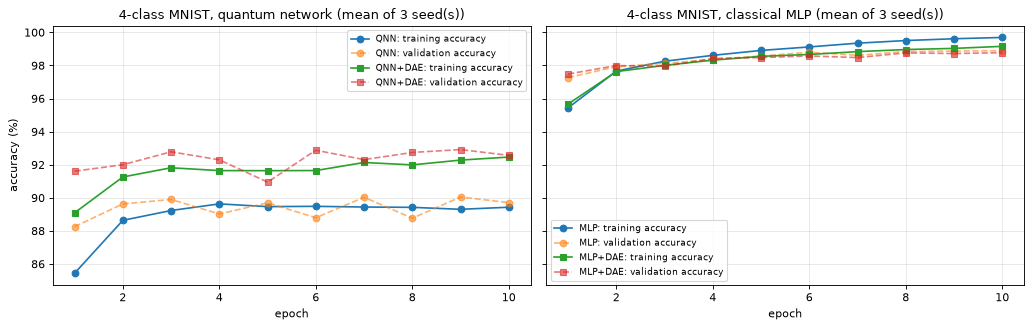

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, fam in zip(axs, ("QNN", "MLP")):
    for key, st in ((fam, "o-"), (fam + "+DAE", "s-")):
        hs = [MN_HIST[s][key] for s in MN_HIST]; ta = np.mean([h.train_acc for h in hs], 0); va = np.mean([h.val_acc for h in hs], 0)
        ax.plot(range(1, len(ta) + 1), ta, st, label=f"{key}: training accuracy"); ax.plot(range(1, len(va) + 1), va, st.replace("-", "--"), alpha=0.6, label=f"{key}: validation accuracy")
    ax.set_xlabel("epoch"); ax.set_title(f"4-class MNIST, {'quantum network' if fam == 'QNN' else 'classical MLP'} (mean of {len(MN_HIST)} seed(s))"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axs[0].set_ylabel("accuracy (%)")
plt.tight_layout(); plt.show()

### Fig. 6: the data and the DAE output (real test images, seed 0)

Rows as in the paper: original, Gaussian-noisy, noisy after the pre-encoding layer, FGSM images (epsilon 0.15, crafted against the plain QNN), FGSM images after the pre-encoding layer.

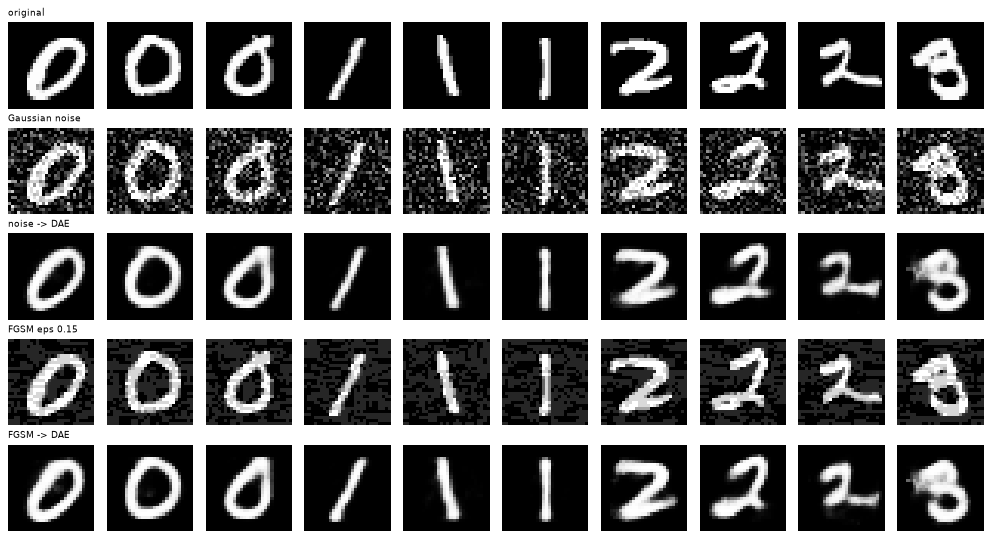

true labels            : [0, 0, 0, 1, 1, 1, 2, 2, 2, 3]
plain QNN on FGSM      : [3, 3, 3, 0, 3, 3, 3, 0, 1, 0]
QNN+DAE on FGSM        : [0, 0, 0, 1, 1, 1, 2, 2, 2, 3]


In [17]:
d0 = MN0["data"]; dae0 = MN0["dae"]; k = 10
sel = []
for c in range(4): sel += np.where(d0["yte"].numpy() == c)[0][:3].tolist()
sel = sel[:k] if len(sel) >= k else sel
Xo = d0["Xte"][sel]; Xn_ = MN0["Xn"][sel]; Xf_ = MN0["Xf"][MNIST_EPS[0]][sel]
with torch.no_grad(): rows = [("original", Xo), ("Gaussian noise", Xn_), ("noise -> DAE", dae0(Xn_)), (f"FGSM eps {MNIST_EPS[0]}", Xf_), ("FGSM -> DAE", dae0(Xf_))]
fig, axs = plt.subplots(5, len(sel), figsize=(1.25 * len(sel), 6.8))
for r_, (nm, X) in enumerate(rows):
    for c in range(len(sel)):
        axs[r_, c].imshow(X[c].reshape(28, 28), cmap="gray", vmin=0, vmax=1); axs[r_, c].axis("off")
        if c == 0: axs[r_, c].set_title(nm, fontsize=8, loc="left")
plt.tight_layout(); plt.show()
pred = lambda m, X: m(X).argmax(1).numpy()
print("true labels            :", [CLASSES[i] for i in d0["yte"][sel].numpy()])
print("plain QNN on FGSM      :", [CLASSES[i] for i in pred(MN0["nets"]["QNN"], Xf_)])
print("QNN+DAE on FGSM        :", [CLASSES[i] for i in pred(MN0["nets"]["QNN+DAE"], Xf_)])

### Dataset Exploration, continued: what the circuit actually receives

After the pre-encoding layer, the 784-dimensional vector that is amplitude-encoded is the DAE output. The plot shows the **real test images**, the real FGSM images, and the DAE outputs projected to two dimensions
(PCA fitted on the clean training images; the same coordinates scaled to $[0, \pi]$ by a scaler fitted on the training split). Points are coloured by ground-truth digit; the middle panel shows how the FGSM images (eps 0.45) drift out of the digit clusters and where the DAE brings them back.

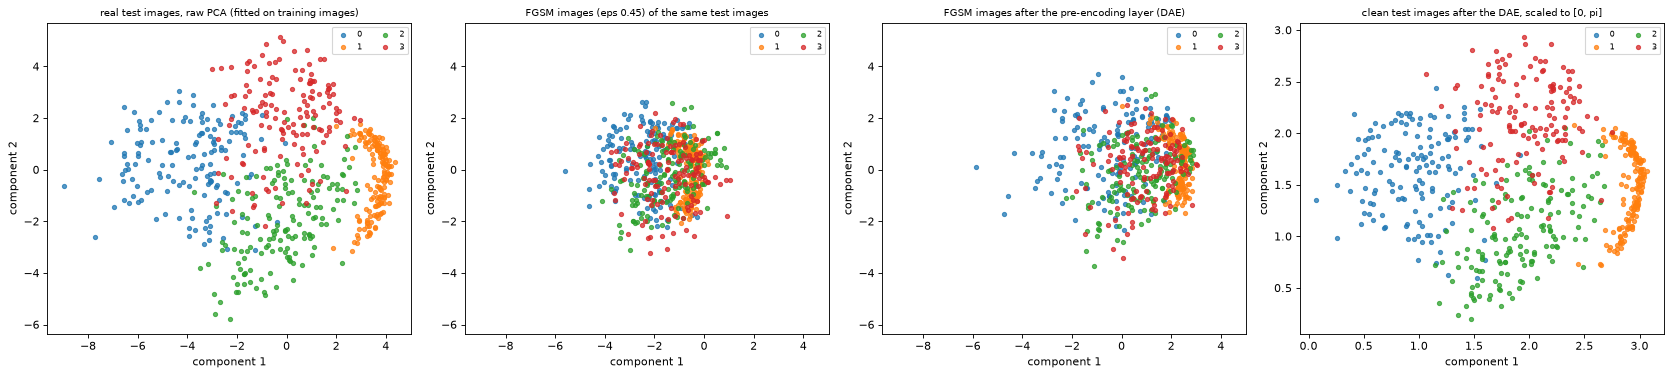

In [18]:
Xtr0 = d0["Xtr"].numpy(); pca0 = PCA(2, random_state=SEED).fit(Xtr0); sc0 = MinMaxScaler((0, math.pi)).fit(pca0.transform(Xtr0))
sub = np.random.default_rng(SEED).choice(len(d0["Xte"]), min(600, len(d0["Xte"])), replace=False); ysub = d0["yte"].numpy()[sub]
Xs = d0["Xte"][sub]; Xs_f = fgsm(MN0["nets"]["QNN"], Xs, d0["yte"][sub], MNIST_EPS[-1], (0, 1))
with torch.no_grad(): Xs_fd = dae0(Xs_f); Xs_d = dae0(Xs)
fig, axs = plt.subplots(1, 4, figsize=(21, 4.8))
names = [str(c) for c in CLASSES]
scatter(axs[0], pca0.transform(Xs.numpy()), ysub, "real test images, raw PCA (fitted on training images)", names)
scatter(axs[1], pca0.transform(Xs_f.numpy()), ysub, f"FGSM images (eps {MNIST_EPS[-1]}) of the same test images", names)
scatter(axs[2], pca0.transform(Xs_fd.numpy()), ysub, "FGSM images after the pre-encoding layer (DAE)", names)
scatter(axs[3], sc0.transform(pca0.transform(Xs_d.numpy())), ysub, "clean test images after the DAE, scaled to [0, pi]", names)
for a in axs[:3]: a.set_xlim(axs[0].get_xlim()); a.set_ylim(axs[0].get_ylim())
plt.tight_layout(); plt.show()

### Table 2: accuracy at epsilon 0.15 / 0.30 / 0.45

Quantum network, accuracy (%) on the test images, mean +- std over 3 seed(s)


QNN       QNN+DAE QNN adv-trained
attack   eps                                            
clean    0.00  90.2 +- 2.6   93.4 +- 1.4     89.7 +- 0.9
static   0.15   2.0 +- 2.7   88.8 +- 2.6     88.0 +- 1.4
         0.30   0.0 +- 0.0   77.9 +- 4.9     83.2 +- 4.3
         0.45   0.0 +- 0.0  43.3 +- 11.5    69.2 +- 11.9
adaptive 0.15   2.0 +- 2.7   68.6 +- 1.7      2.1 +- 1.1
         0.30   0.0 +- 0.0   30.8 +- 8.7      0.0 +- 0.0
         0.45   0.0 +- 0.0    9.8 +- 3.6      0.0 +- 0.0

Classical MLP counterpart


MLP      MLP+DAE MLP adv-trained
attack   eps                                           
clean    0.00  99.2 +- 0.0  99.2 +- 0.0     99.2 +- 0.1
static   0.15   4.3 +- 2.6  93.5 +- 0.2     99.9 +- 0.0
         0.30   0.6 +- 0.7  44.3 +- 5.2    100.0 +- 0.0
         0.45   0.1 +- 0.1   6.0 +- 1.7    100.0 +- 0.0
adaptive 0.15   4.3 +- 2.6  74.4 +- 1.6      1.5 +- 1.4
         0.30   0.6 +- 0.7  19.3 +- 3.8      0.0 +- 0.0
         0.45   0.1 +- 0.1   5.8 +- 2.0      0.0 +- 0.0

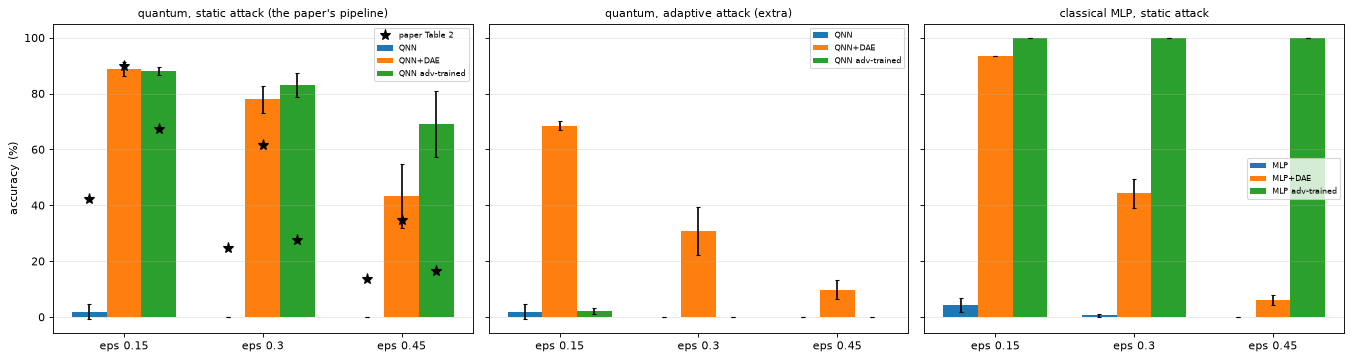

In [19]:
def table_models(df, fam):
    rows = []
    for mode in ("clean", "static", "adaptive"):
        for e in ((0.0,) if mode == "clean" else MNIST_EPS):
            r = {"attack": mode, "eps": e}
            for nm in (fam, fam + "+DAE", fam + " adv-trained"):
                s = df[(df.model == nm) & (df["mode"] == mode) & (df.eps == e)].acc
                r[nm] = f"{s.mean():.1f} +- {s.std() if len(s) > 1 else 0:.1f}"
            rows.append(r)
    return pd.DataFrame(rows).set_index(["attack", "eps"])
print("Quantum network, accuracy (%%) on the test images, mean +- std over %d seed(s)" % MNIST_SEEDS); display(table_models(MR, "QNN"))
print("Classical MLP counterpart"); display(table_models(MR, "MLP"))

fig, axs = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
PAPER2 = {0.15: (42.2, 89.9, 67.4), 0.30: (24.6, 61.6, 27.5), 0.45: (13.7, 34.9, 16.4)}
for ax, (fam, mode, ttl) in zip(axs, (("QNN", "static", "quantum, static attack (the paper's pipeline)"), ("QNN", "adaptive", "quantum, adaptive attack (extra)"), ("MLP", "static", "classical MLP, static attack"))):
    w = 0.25
    for j, nm in enumerate((fam, fam + "+DAE", fam + " adv-trained")):
        s = [MR[(MR.model == nm) & (MR["mode"] == mode) & (MR.eps == e)].acc for e in MNIST_EPS]
        ax.bar(np.arange(3) + (j - 1) * w, [x.mean() for x in s], w, yerr=[x.std() if len(x) > 1 else 0 for x in s], capsize=2, label=nm)
        if fam == "QNN" and mode == "static": ax.plot(np.arange(3) + (j - 1) * w, [PAPER2[e][j] for e in MNIST_EPS], "k*", ms=10, label="paper Table 2" if j == 0 else None)
    ax.set_xticks(range(3)); ax.set_xticklabels([f"eps {e}" for e in MNIST_EPS]); ax.set_title(ttl, fontsize=10); ax.legend(fontsize=7); ax.grid(alpha=0.3, axis="y")
axs[0].set_ylabel("accuracy (%)")
plt.tight_layout(); plt.show()

In [20]:
# ---- the same similarity metrics as Table 1, for MNIST (mean over seeds) ----
display(MREC.groupby(["data", "stage"])[["mse", "cos"]].mean().round(4).reindex(["noisy", *[f"fgsm {e}" for e in MNIST_EPS]], level=0))
# ---- training cost: separate DAE versus adversarial training (seconds of wall-clock time, mean over seeds) ----
tc = MTIME.drop(columns="seed").mean().round(1).to_frame("seconds"); display(tc)
# ---- simulator against the PennyLane QNode again, now with the trained weights and the trained DAE outputs ----
with torch.no_grad(): Xchk = MN0["dae"](MN0["data"]["Xte"][:6])
print("trained QNN+DAE on DAE outputs of real test images: max diff %.2e" % check_equivalence(SIM_MNIST, QN_MNIST, encode_amp, MN0["nets"]["QNN+DAE"].W, Xchk))
print("trained plain QNN on real test images           : max diff %.2e" % check_equivalence(SIM_MNIST, QN_MNIST, encode_amp, MN0["nets"]["QNN"].W, MN0["data"]["Xte"]))
print("trained Iris QNN on real flowers                : max diff %.2e" % check_equivalence(SIM_IRIS, QN_IRIS, encode_angle, IRIS0[0]["QNN"].W, IRIS0[3]))

mse     cos
data      stage                 
noisy     after   0.0110  0.9478
          before  0.0466  0.8034
fgsm 0.15 after   0.0112  0.9492
          before  0.0124  0.9366
fgsm 0.3  after   0.0169  0.9187
          before  0.0483  0.7903
fgsm 0.45 after   0.0456  0.7687
          before  0.1065  0.6323

,seconds
DAE,99.4
QNN plain,267.9
QNN+DAE,325.5
QNN adv-trained (incl. FGSM generation),375.8
MLP plain,18.4
MLP+DAE,30.3
MLP adv-trained (incl. FGSM generation),24.7


trained QNN+DAE on DAE outputs of real test images: max diff 7.96e-14


trained plain QNN on real test images           : max diff 4.60e-14
trained Iris QNN on real flowers                : max diff 4.44e-16


## 6. Side by side with the paper

Rule for the numeric rows: a value is **reproduced** if it lies within 2 accuracy points (0.02 for MSE and cosine similarity) of the paper's value, **not reached** if ours is lower by more, **exceeded** if ours is higher by more.
The paper reports one run; the notebook value is the mean over seeds (the standard deviation is in the tables above, and the Iris test set has only 30 flowers, so one flower is 3.3 points).
The main Table 2 column uses the **static** attack (the paper's pipeline, one adversarial test set per epsilon, crafted against the plain QNN and evaluated on all three networks); the adaptive numbers are an extra that the paper does not report.

In [21]:
def verdict(paper, ours, tol):
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    return ("exceeded by %.3g" % d) if d > 0 else ("not reached by %.3g" % -d)

rows = []
# Table 1 (Iris)
for (dta, stg), (pm, pc) in PAPER_T1.items():
    sub_ = IREC[(IREC.data == dta) & (IREC.stage == stg)]
    rows.append(dict(source="Table 1, Iris", item=f"{dta} data, {stg} DAE: MSE", paper=pm, notebook=round(sub_.mse.mean(), 3), verdict=verdict(pm, sub_.mse.mean(), 0.02)))
    rows.append(dict(source="Table 1, Iris", item=f"{dta} data, {stg} DAE: cosine similarity", paper=pc, notebook=round(sub_.cos.mean(), 3), verdict=verdict(pc, sub_.cos.mean(), 0.02)))
# Fig. 4 text values (Iris, QNN with the layer, static attack)
for units, lab in (("[0,1] units", "Fig. 4 text, Iris, main reading"), ("z-score units", "Fig. 4 text, Iris, z-score sensitivity")):
    for eps, pv in zip(IRIS_EPS, (93.3, 90.0, 86.67, 73.33)):
        ours = IR[(IR.model == "QNN+DAE") & (IR.units == units) & (IR["mode"] == "static") & (IR.eps == eps)].acc.mean()
        rows.append(dict(source=lab, item=f"accuracy with layer, eps {eps}", paper=pv, notebook=round(ours, 1), verdict=verdict(pv, ours, 2.0)))
# Table 2 (MNIST): static attack = main reading; adaptive attack = extra
for md_, lab in (("static", "Table 2, MNIST, static attack (main)"), ("adaptive", "Table 2, MNIST, adaptive attack (extra)")):
    for eps, pv in PAPER2.items():
        for j, nm in enumerate(("QNN", "QNN+DAE", "QNN adv-trained")):
            ours = MR[(MR.model == nm) & (MR["mode"] == md_) & (MR.eps == eps)].acc.mean()
            rows.append(dict(source=lab, item=f"{('Non-preproc', 'Preproc', 'Adv-training')[j]}, eps {eps}", paper=pv[j], notebook=round(ours, 1), verdict=verdict(pv[j], ours, 2.0)))
CMP = pd.DataFrame(rows)
pd.set_option("display.width", 200); pd.set_option("display.max_rows", 100)
display(CMP.set_index(["source", "item"]))
print("verdict counts over the %d numeric cells:" % len(CMP), CMP.verdict.str.split(" by ").str[0].value_counts().to_dict())

paper  notebook                verdict
source                                  item                                                                              
Table 1, Iris                           noisy data, before DAE: MSE                 0.263     0.256             reproduced
                                        noisy data, before DAE: cosine similarity   0.832     0.690   not reached by 0.142
                                        noisy data, after DAE: MSE                  0.173     0.045   not reached by 0.128
                                        noisy data, after DAE: cosine similarity    0.895     0.924     exceeded by 0.0292
                                        fgsm data, before DAE: MSE                  0.211     0.203             reproduced
                                        fgsm data, before DAE: cosine similarity    0.873     0.668   not reached by 0.205
                                        fgsm data, after DAE: MSE                   0.176     0.075   not reached by 0.101
                                        fgsm data, after DAE: cosine similarity     0.910     0.870  not reached by 0.0399
Fig. 4 text, Iris, main reading         accuracy with layer, eps 0.15              93.300    59.000    not reached by 34.3
                                        accuracy with layer, eps 0.3               90.000    35.500    not reached by 54.5
                                        accuracy with layer, eps 0.45              86.670    22.700      not reached by 64
                                        accuracy with layer, eps 0.6               73.330    14.500    not reached by 58.8
Fig. 4 text, Iris, z-score sensitivity  accuracy with layer, eps 0.15              93.300    79.000    not reached by 14.3
                                        accuracy with layer, eps 0.3               90.000    73.200    not reached by 16.8
                                        accuracy with layer, eps 0.45              86.670    64.500    not reached by 22.2
                                        accuracy with layer, eps 0.6               73.330    49.500    not reached by 23.8
Table 2, MNIST, static attack (main)    Non-preproc, eps 0.15                      42.200     2.000    not reached by 40.2
                                        Preproc, eps 0.15                          89.900    88.800             reproduced
                                        Adv-training, eps 0.15                     67.400    88.000       exceeded by 20.6
                                        Non-preproc, eps 0.3                       24.600     0.000    not reached by 24.6
                                        Preproc, eps 0.3                           61.600    77.900       exceeded by 16.3
                                        Adv-training, eps 0.3                      27.500    83.200       exceeded by 55.7
                                        Non-preproc, eps 0.45                      13.700     0.000    not reached by 13.7
                                        Preproc, eps 0.45                          34.900    43.300       exceeded by 8.42
                                        Adv-training, eps 0.45                     16.400    69.200       exceeded by 52.8
Table 2, MNIST, adaptive attack (extra) Non-preproc, eps 0.15                      42.200     2.000    not reached by 40.2
                                        Preproc, eps 0.15                          89.900    68.600    not reached by 21.3
                                        Adv-training, eps 0.15                     67.400     2.100    not reached by 65.3
                                        Non-preproc, eps 0.3                       24.600     0.000    not reached by 24.6
                                        Preproc, eps 0.3                           61.600    30.800    not reached by 30.8
                                        Adv-training, eps 0.3                      27.500     0.000    not reached by 27.5
                         

verdict counts over the 34 numeric cells: {'not reached': 25, 'exceeded': 6, 'reproduced': 3}


In [22]:
# ---- the qualitative claims of the paper, evaluated on our numbers ----
def m_(df, model, mode, eps): return df[(df.model == model) & (df["mode"] == mode) & (df.eps == eps)].acc.mean()
claims = []
def add(text, ok, detail, paper_says, verdict_override=None):
    claims.append(dict(claim=text, paper=paper_says, notebook=detail, verdict=verdict_override or ("reproduced" if ok else "not reached")))

for dta in ("noisy", "fgsm"):
    b = IREC[(IREC.data == dta) & (IREC.stage == "before")][["mse", "cos"]].mean(); a = IREC[(IREC.data == dta) & (IREC.stage == "after")][["mse", "cos"]].mean()
    add(f"Iris: the pre-encoding layer lowers the MSE and raises the cosine similarity of {dta} data", a.mse < b.mse and a.cos > b.cos,
        f"MSE {b.mse:.3f} -> {a.mse:.3f}, cosine {b.cos:.3f} -> {a.cos:.3f}", "yes (Table 1)")
for units in ("[0,1] units", "z-score units"):
    sub_ = IR[IR.units == units]
    q_gain = [m_(sub_, "QNN+DAE", "static", e) - m_(sub_, "QNN", "static", e) for e in IRIS_EPS]
    add(f"Iris ({units}): the QNN with the layer is more accurate than the plain QNN under FGSM at every epsilon (static attack)", all(g > 0 for g in q_gain),
        "gain in points per eps: " + ", ".join(f"{g:+.1f}" for g in q_gain), "yes (Fig. 4, graph only)")
    acc_dae = [m_(sub_, "QNN+DAE", "static", e) for e in IRIS_EPS]
    add(f"Iris ({units}): accuracy with the layer decreases monotonically with epsilon", all(x >= y for x, y in zip(acc_dae, acc_dae[1:])), ", ".join(f"{x:.1f}" for x in acc_dae), "93.3, 90, 86.67, 73.33")
dclean = m_(MR, "QNN+DAE", "clean", 0.0) - m_(MR, "QNN", "clean", 0.0)
add("MNIST: the layer does not change the clean accuracy of the QNN (|difference| <= 2 points)", abs(dclean) <= 2.0,
    f"QNN {m_(MR, 'QNN', 'clean', 0.0):.1f} %, QNN+DAE {m_(MR, 'QNN+DAE', 'clean', 0.0):.1f} % (difference {dclean:+.1f})", "'basically does not affect' (Fig. 5)")
st = {nm: [m_(MR, nm, "static", e) for e in MNIST_EPS] for nm in ("QNN", "QNN+DAE", "QNN adv-trained")}
add("MNIST: QNN with the layer beats the plain QNN at all three epsilons (static attack)", all(a > b for a, b in zip(st["QNN+DAE"], st["QNN"])),
    "; ".join(f"eps {e}: {b:.1f} -> {a:.1f}" for e, a, b in zip(MNIST_EPS, st["QNN+DAE"], st["QNN"])), "42.2 -> 89.9, 24.6 -> 61.6, 13.7 -> 34.9")
add("MNIST: QNN with the layer beats the adversarially trained QNN at all three epsilons (static attack)", all(a > b for a, b in zip(st["QNN+DAE"], st["QNN adv-trained"])),
    "; ".join(f"eps {e}: adv-trained {b:.1f} vs layer {a:.1f}" for e, a, b in zip(MNIST_EPS, st["QNN+DAE"], st["QNN adv-trained"])), "67.4/27.5/16.4 vs 89.9/61.6/34.9")
add("MNIST: adversarial training improves on the plain QNN at all three epsilons (paper's baseline works)", all(a > b for a, b in zip(st["QNN adv-trained"], st["QNN"])),
    "; ".join(f"eps {e}: {b:.1f} -> {a:.1f}" for e, a, b in zip(MNIST_EPS, st["QNN adv-trained"], st["QNN"])), "42.2 -> 67.4, 24.6 -> 27.5, 13.7 -> 16.4")
tq = MTIME.mean(numeric_only=True)
add("Cost: training the separate layer is cheaper than adversarial training of the QNN (wall-clock)", tq["DAE"] < tq["QNN adv-trained (incl. FGSM generation)"],
    f"DAE {tq['DAE']:.0f} s versus adversarial training {tq['QNN adv-trained (incl. FGSM generation)']:.0f} s (plain QNN training {tq['QNN plain']:.0f} s)", "'significantly reducing the complexity' (no numbers)")
ad = {nm: [m_(MR, nm, "adaptive", e) for e in MNIST_EPS] for nm in ("QNN", "QNN+DAE", "QNN adv-trained")}
add("MNIST (adaptive attack, extra): QNN with the layer beats the adversarially trained QNN at all three epsilons", all(a > b for a, b in zip(ad["QNN+DAE"], ad["QNN adv-trained"])),
    "; ".join(f"eps {e}: adv-trained {b:.1f} vs layer {a:.1f}" for e, a, b in zip(MNIST_EPS, ad["QNN+DAE"], ad["QNN adv-trained"])), "67.4/27.5/16.4 vs 89.9/61.6/34.9 (attack type not specified)")
add("Extra, not tested in the paper: the advantage of the layer survives an adaptive attack that differentiates through the DAE", all(a > b for a, b in zip(ad["QNN+DAE"], ad["QNN"])),
    "adaptive accuracy QNN+DAE vs plain: " + "; ".join(f"eps {e}: {a:.1f} vs {b:.1f}" for e, a, b in zip(MNIST_EPS, ad["QNN+DAE"], ad["QNN"])), "not reported", "cannot be checked (not in the paper); measured: " + ("holds" if all(a > b for a, b in zip(ad["QNN+DAE"], ad["QNN"])) else "does not hold"))
mst = {nm: [m_(MR, nm, "static", e) for e in MNIST_EPS] for nm in ("MLP", "MLP+DAE")}
add("Extra, not tested in the paper: the same layer helps a classical MLP just as much (classical counterpart)", all(a > b for a, b in zip(mst["MLP+DAE"], mst["MLP"])),
    "static accuracy MLP+DAE vs MLP: " + "; ".join(f"eps {e}: {a:.1f} vs {b:.1f}" for e, a, b in zip(MNIST_EPS, mst["MLP+DAE"], mst["MLP"])), "not reported", "cannot be checked (not in the paper); measured: " + ("helps" if all(a > b for a, b in zip(mst["MLP+DAE"], mst["MLP"])) else "does not consistently help"))
CL = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 170)
display(CL.set_index("claim"))
print("verdicts:", CL.verdict.str.split(" \\(").str[0].value_counts().to_dict())

,paper,notebook,verdict
claim,,,
Iris: the pre-encoding layer lowers the MSE and raises the cosine similarity of noisy data,yes (Table 1),"MSE 0.256 -> 0.045, cosine 0.690 -> 0.924",reproduced
Iris: the pre-encoding layer lowers the MSE and raises the cosine similarity of fgsm data,yes (Table 1),"MSE 0.203 -> 0.075, cosine 0.668 -> 0.870",reproduced
"Iris ([0,1] units): the QNN with the layer is more accurate than the plain QNN under FGSM at every epsilon (static attack)","yes (Fig. 4, graph only)","gain in points per eps: +18.0, +26.8, +10.8, -9.0",not reached
"Iris ([0,1] units): accuracy with the layer decreases monotonically with epsilon","93.3, 90, 86.67, 73.33","59.0, 35.5, 22.7, 14.5",reproduced
Iris (z-score units): the QNN with the layer is more accurate than the plain QNN under FGSM at every epsilon (static attack),"yes (Fig. 4, graph only)","gain in points per eps: -7.8, +1.8, +10.3, +19.7",not reached
Iris (z-score units): accuracy with the layer decreases monotonically with epsilon,"93.3, 90, 86.67, 73.33","79.0, 73.2, 64.5, 49.5",reproduced
MNIST: the layer does not change the clean accuracy of the QNN (|difference| <= 2 points),'basically does not affect' (Fig. 5),"QNN 90.2 %, QNN+DAE 93.4 % (difference +3.2)",not reached
MNIST: QNN with the layer beats the plain QNN at all three epsilons (static attack),"42.2 -> 89.9, 24.6 -> 61.6, 13.7 -> 34.9",eps 0.15: 2.0 -> 88.8; eps 0.3: 0.0 -> 77.9; eps 0.45: 0.0 -> 43.3,reproduced
MNIST: QNN with the layer beats the adversarially trained QNN at all three epsilons (static attack),67.4/27.5/16.4 vs 89.9/61.6/34.9,eps 0.15: adv-trained 88.0 vs layer 88.8; eps 0.3: adv-trained 83.2 vs layer 77.9; eps 0.45: adv-trained 69.2 vs layer 43.3,not reached


verdicts: {'reproduced': 8, 'not reached': 4, 'cannot be checked': 2}


### Summary of the verdicts

The tables above are generated by the recorded run (`FAST_MODE = False`: Iris 20 seeds, MNIST digits 0-3 with all 24,754 training / 4,157 test images, 3 seeds; 66.8 minutes of wall-clock time on a CPU shared with other jobs). In words:

* **Reproduced.** (i) The MSE of the noisy and of the FGSM Iris data before the layer (0.256 and 0.203 against 0.263 and 0.211, which also fixes sigma and epsilon of the setting), and the direction of the effect of the layer in Table 1: MSE down and cosine similarity up for both noisy and FGSM data.
  (ii) On 4-class MNIST the QNN with the pre-encoding layer is far more accurate than the plain QNN under the paper's (static) FGSM pipeline at all three epsilons (88.8 / 77.9 / 43.3 % against 2.0 / 0.0 / 0.0 %); at epsilon 0.15 it matches the paper's 89.9 % within the tolerance (88.8 %).
  (iii) Adversarial training improves on the plain QNN, as in the paper's baseline. (iv) Training the separate layer is cheaper than adversarial training (99 s against 376 s of CPU time, with the plain QNN training taking 268 s).
* **Not reached or exceeded.** (i) The plain QNN is much more vulnerable here than in the paper (2.0 / 0.0 / 0.0 % against 42.2 / 24.6 / 13.7 %; below the 25 % chance level of a 4-class problem), probably because of our amplitude-encoded 10-qubit circuit; the paper's circuit is unknown.
  (ii) Our preprocessing layer is better than the paper's at epsilon 0.30 and 0.45 (77.9 / 43.3 % against 61.6 / 34.9 %), and our adversarially trained QNN is much better than the paper's (88.0 / 83.2 / 69.2 % against 67.4 / 27.5 / 16.4 %) under the static attack, so the paper's headline ordering "layer beats adversarial training" is **not reached** in the static setting (tie at 0.15, adversarial training ahead at 0.30 and 0.45).
  It holds under the adaptive attack (68.6 / 30.8 / 9.8 % against 2.1 / 0.0 / 0.0 %), which the paper does not test. (iii) The claim that the layer does not change the clean accuracy: ours is 3.2 points higher with the layer (93.4 against 90.2 %, standard deviations 1.4 and 2.6 over 3 seeds), so the claim holds in spirit but not within 2 points.
  (iv) Iris, Fig. 4: with epsilon in [0, 1] units the accuracies with the layer are 59.0 / 35.5 / 22.7 / 14.5 % and with epsilon in standard-deviation units (a sensitivity reading added after the first run) 79.0 / 73.2 / 64.5 / 49.5 %, both below the paper's 93.3 / 90 / 86.67 / 73.33 %; the layer helps in the main reading at epsilon 0.15 to 0.45 (+18.0, +26.8, +10.8 points) but not at 0.60 (-9.0), and in the second reading at epsilon 0.30 and above but not at 0.15 (-7.8), because it lowers the clean accuracy (86.3 against 95.3 %, with two of the 20 seeds in which the DAE collapses and both layer models stay at 33 %).
  (v) Iris Table 1: after the layer our MSE is much lower than the paper's (0.045 and 0.075 against 0.173 and 0.176) and the cosine similarity of the original data differs because our scaled data has a norm of 0.98 where the paper's cosine values imply about 1.5 to 1.6, so the Iris data in the paper was scaled differently.
* **Cannot be checked.** The Iris accuracy of the plain QNN (the paper shows it only in a figure), the data and the circuit of the paper, and whether the paper's adversarially trained model was tested on the transferred or on a fresh attack.
* **Extras (not in the paper).** The adaptive attack that differentiates through the layer removes most of the benefit (MNIST 68.6 / 30.8 / 9.8 % at the three epsilons, from 88.8 / 77.9 / 43.3 % static); the classical MLP with the same layer also gains a lot (static 93.5 / 44.3 / 6.0 % against 4.3 / 0.6 / 0.1 % without it), so the effect is not specific to the quantum circuit;
  adversarial training of the QNN and of the MLP scores 69 to 100 % on the transferred images but collapses to 0 to 2 % under the adaptive attack, which shows that the static evaluation of the paper is the weakest way to compare the two defences.

**Overall status: partially reproduced.** The pipeline and the qualitative effect of the pre-encoding layer are reproduced; most absolute accuracies are not, because the paper omits the circuit, the data scaling and the attack protocol, and the strongest claim (beating adversarial training) depends on the attack being non-adaptive and on the training recipe of the baseline.


In [23]:
print("Notebook finished. FAST_MODE =", FAST_MODE, "| total wall-clock %.1f min" % ((time.time() - T_START) / 60))
print("Iris rows:", len(IR), "| MNIST rows:", len(MR), "| MNIST seeds:", MNIST_SEEDS, "| Iris seeds:", IRIS_SEEDS)

Notebook finished. FAST_MODE = False | total wall-clock 65.2 min
Iris rows: 1440 | MNIST rows: 144 | MNIST seeds: 3 | Iris seeds: 20


## Reading the paper critically

* **The paper is a short workshop paper without code.** The circuit, the encoding, the autoencoder size, the noise level, the training set sizes, the optimiser, the exact classes of the 4-class MNIST task and the adversarial-training recipe are all missing. This notebook fills them in (table at the top); the numbers depend on those choices.
* **The main evaluation is a transfer ("static") attack.** Fig. 6 shows that the adversarial images are generated first and *then* passed through the pre-encoding layer, i.e. the attacker does not know about the denoiser. This is the weakest meaningful threat model.
  A defence that removes the perturbation of a non-adaptive attack says little about an attacker who differentiates through the autoencoder (BPDA / full white-box). The adaptive rows above are the first test of that; the paper has none. A plain adversarially trained network is evaluated on the same transferred images, which is also non-adaptive.
* **Iris with 30 test flowers.** Each flower is 3.3 accuracy points; a single split cannot show a difference of a few points. The paper reports a single run without confidence intervals; this notebook averages over seeds.
* **The Gaussian-noise level and the DAE size decide Table 1.** A bottleneck-2 autoencoder on a nearly two-dimensional dataset removes noise well, so the reconstruction error depends mostly on how much of the noise lies in the retained directions. The paper's MSE of 0.263 after noise corresponds to sigma of about 0.5 on features scaled to [0, 1].
* **No classical counterpart in the paper.** The abstract speaks of quantum robustness, but any classifier behind a denoiser gets the same boost. The classical MLP rows above show whether the effect is specific to the quantum circuit. A quantum-specific claim would need the comparison to be made on identical inputs, which the paper does not do.
* **"High robustness" is relative.** At epsilon 0.45 on MNIST, the paper's best model is at 34.9 % on a 4-class problem (25 % is chance) and an FGSM step of 0.45 is a large visible perturbation; the claim is a statement about a small perturbation range.
* **Cost argument.** Training the autoencoder separately is cheap, but the attacker-independent denoiser must be retrained when the data distribution changes, and the QNN still has to be trained on top of it. The wall-clock comparison above is a CPU-simulator measurement, not a hardware cost.
* **Amplitude encoding.** With amplitude encoding the input is normalised, so a perturbation that scales the image has no effect and a perturbation changes the state only through its direction. This helps the plain QNN a little and changes how epsilon translates into state distance.
* **The denoiser is a single point of failure.** In two of the 20 Iris seeds (55 and 56) the autoencoder collapsed during training and both layer models fell to 33 % clean accuracy; a frozen preprocessing layer needs its own validation, which the paper never shows.
* **The static adversarially-trained baseline is contaminated.** The adversarial training images are crafted against the plain QNN and the static test images are crafted against the same network, so the adversarially trained model has seen almost the same perturbations (hence 69 to 100 % static and 0 to 2 % adaptive here). A fair comparison needs adversarial test images generated against each model.

## Exercises

1. **Noise level.** Change `IRIS_SIGMA` to 0.25 and to 1.0 and recompute Table 1 and Fig. 4. How does the MSE gap before and after the layer change?
2. **Adaptive attack.** Replace FGSM by a 10-step PGD with random start in `fgsm` (L-infinity, step eps/4) and compare the static and adaptive columns of Table 2. Does the DAE still help?
3. **Depth.** Set `M_LAYERS` to 2 and to 8. Is the plain QNN's vulnerability related to circuit depth, as the abstract claims ("as the complexity increases, the vulnerability also grows")?
4. **Adversarial training budget.** Raise `ADV_FRACTION` to 1.0 and add a fourth epsilon (0.6) to the mixture. How much of the gap to the pre-encoding layer closes, and at what training cost?
5. **Other encodings.** Replace amplitude encoding of the 784 pixels by angle encoding of the first 8 PCA components (fitted on the training split). Does the effect of the pre-encoding layer depend on the encoding?